# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 3: 30-Day Spending Prediction (Bayes-Optimal V3 Huber-Anchor & 5-Family Q_FINE Hurdle)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task3/task3_monthly_spending.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Instructor:** Dr. Boonyarit Changaival  
**Department:** Department of Computer Engineering, Faculty of Engineering, King Mongkut's University of Technology Thonburi  

---

### Table of Contents
1. [Executive Summary & Problem Formulation](#1-executive-summary--problem-formulation)
2. [Environment Setup & Automated Platform Detection](#2-environment-setup--automated-platform-detection)
3. [Data Ingestion & Exploratory Data Analysis (EDA)](#3-data-ingestion--exploratory-data-analysis-eda)
4. [Domain-Driven Financial Feature Engineering](#4-domain-driven-financial-feature-engineering)
5. [Stratified Cross-Validation Strategy](#5-stratified-cross-validation-strategy)
6. [Bayes-Optimal V3 Stage-1 (6-Model) & 5-Family Q_FINE Stage-2 Architecture](#6-bayes-optimal-v3-stage-1-6-model--5-family-q_fine-stage-2-architecture)
7. [Nested OOF Calibration, Paired Bootstrap & Promotion Gate](#7-nested-oof-calibration-paired-bootstrap--promotion-gate)
8. [Comprehensive Diagnostic Visualizations & Error Analysis](#8-comprehensive-diagnostic-visualizations--error-analysis)
9. [Quantitative Ablation Benchmark & Model Summary](#9-quantitative-ablation-benchmark--model-summary)
10. [Test Set Predictions, Quality Assurance & Artifact Export](#10-test-set-predictions-quality-assurance--artifact-export)
11. [Conclusion & Technical Key Takeaways](#11-conclusion--technical-key-takeaways)


## 1. Executive Summary & Problem Formulation

This investigation addresses **Task 3: Monthly Spending Prediction** within the CPE 342 Kaggle Player Intelligence System. The goal is to accurately forecast the 30-day forward monetary expenditure (`spending_30d` in Thai Baht, THB) for $N = 25,889$ test accounts based on 32 behavioral, engagement, and historical transactional signals.

### 1.1 Business Importance & Quantitative Challenge
The training target exhibits severe zero-inflation (**48.12%** non-spenders with `spending_30d == 0`) coupled with an extreme Pareto right tail extending up to `300,000 THB`. Single-stage log-space regressors suffer from exponential re-transformation bias, while standard expected-value hurdles ($p \cdot \hat{y}$) misalign with the competition $L_1$ loss metric.

### 1.2 Mathematical Optimal Bayes Rule for NMAE
Submissions are evaluated on the competition-custom **Normalized Mean Absolute Error (NMAE)**:
$$\text{NMAE} = \frac{1}{1 + \frac{\sum_{i=1}^N |y_i - \hat{y}_i|}{\sum_{i=1}^N y_i}}$$
Under $L_1$ geometry, the mathematically optimal prediction is the **$1 - \frac{1}{2p}$ conditional quantile** of $(Y \mid Y > 0, X)$ whenever $p = P(Y > 0 \mid X) > 0.5$ (and $0$ otherwise).

### 1.3 Verified Result Summary
Using deterministic identity reconstruction, fold-safe coupled missing-value imputation + segment-conditioned V3 imputation (`LGBMClassifier + CatBoost`), calibrated 6-family Stage-1 probabilities on `S1_V3` (`LGBM`, `FineBin1023`, `CatBoost`, `XGBoost`, `LogReg`, PyTorch `TabM_MPS`), and a Stage-2 Log-Linear `Huber(epsilon=1.35)` residual **5-Family 15-Quantile Stack** (`CatBoost Depth-5 V3`, Early-Stopped `XGBoost Depth-5 V3`, Early-Stopped `LightGBM Depth-6 V3`, 4-seed PyTorch `TabMQ_V2` BatchEnsemble $k=16$, and 3-seed PyTorch `TabMQ_Cmp3L` 3-Layer Skip BatchEnsemble $k=16$), our promoted Run 16 pipeline achieves a **Nested 5-Fold Outer OOF NMAE = `0.795996` (`MAE = 2,690.26 THB`)**, improving over our Run 15 Champion (`0.795986`), Run 14 Champion (`0.795275`, `+0.000721`), the Log-Linear Ridge Reference (`0.792770`, **`+0.003226`**, 95% paired CI `[+0.002814, +0.003642]`), and the external baseline (`0.789609`, `+0.006387`).


## 2. Environment Setup & Automated Platform Detection

This section initializes the execution environment. The pipeline automatically detects whether the runtime is **Google Colab**, **Kaggle Notebooks**, or a **Local Workspace**, installs necessary libraries if absent, configures deterministic pseudo-random seeds, and resolves already-attached or locally supplied data only; it does not download datasets.

In [1]:
%matplotlib inline
import os
import sys
import gc
import json
import time
import shutil
import random
import hashlib
import zipfile
import warnings
import subprocess
from pathlib import Path
from importlib.metadata import version as package_version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')

IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("Runtime Platform: Google Colab")
    for pkg in ['lightgbm', 'catboost', 'xgboost', 'scikit-learn']:
        try:
            __import__(pkg.replace('-', '_'))
        except ImportError:
            os.system(f"pip install -q {pkg}")
elif IS_KAGGLE:
    print("Runtime Platform: Kaggle Notebook")
else:
    print("Runtime Platform: Local Workspace")

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.getcwd()
TASK_NAME = 'task3'
candidate_data_dirs = [
    'data',
    os.path.join(BASE_DIR, 'data'),
    os.path.join(BASE_DIR, f'project/{TASK_NAME}/data'),
    os.path.join(BASE_DIR, f'{TASK_NAME}/data'),
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/{TASK_NAME}',
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/CPE342-Hackathon/{TASK_NAME}',
    f'/kaggle/input/{TASK_NAME}',
    f'/content/{TASK_NAME}/data',
    f'/content/data',
]
DATA_DIR = next((d for d in candidate_data_dirs
                 if os.path.isfile(os.path.join(d, "train.csv"))
                 and os.path.isfile(os.path.join(d, "test.csv"))), None)
if DATA_DIR is None and IS_COLAB:
    os.system("git clone --depth 1 https://github.com/Palapluem/cpe342-machine-learning-2026.git /content/repo")
    DATA_DIR = f"/content/repo/project/{TASK_NAME}/data"
if DATA_DIR is None:
    raise FileNotFoundError("Attach the competition data or supply local train.csv/test.csv; no download is attempted.")

TASK_ROOT = os.path.dirname(os.path.abspath(DATA_DIR))
if IS_KAGGLE:
    RUN_DIR = "/kaggle/working/task3_candidate_run"
elif IS_COLAB:
    RUN_DIR = "/content/task3_candidate_run"
else:
    import tempfile
    RUN_DIR = tempfile.mkdtemp(prefix="task3-candidate-")

PRED_DIR = os.path.join(RUN_DIR, "predictions")
ASSETS_DIR = os.path.join(RUN_DIR, "assets")
MODELS_DIR = os.path.join(RUN_DIR, "models")
SUBMIT_DIR = os.path.join(RUN_DIR, "submit")
for output_dir in [PRED_DIR, ASSETS_DIR, MODELS_DIR, SUBMIT_DIR]:
    os.makedirs(output_dir, exist_ok=True)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

print(f"[STATUS] Read-only data input   : {os.path.abspath(DATA_DIR)}")
print(f"[STATUS] Candidate output stage : {os.path.abspath(RUN_DIR)}")
print(f"[STATUS] Target canonical root  : {TASK_ROOT}")


Runtime Platform: Local Workspace
[STATUS] Read-only data input   : /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/data
[STATUS] Candidate output stage : /var/folders/31/4l912k656c3397rqq0m_sc5c0000gn/T/task3-candidate-v4mvap2l
[STATUS] Target canonical root  : /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3


## 3. Data Ingestion & Exploratory Data Analysis (EDA)

In this section, we ingest the $104,000$ training records and $25,889$ test records, perform schema and data integrity audits, quantify the exact rate of zero-inflation, and examine the distributional properties of spending across behavioral player segments.

In [2]:
# -------------------------------------------------------------------------
# Step 3.1: Data Ingestion & Schema Verification
# -------------------------------------------------------------------------
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

print(f"Training Cohort Shape:   {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"Test Cohort Shape:       {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
print(f"Missing Values (Train):  {train_df.isna().sum().sum()}")
print(f"Missing Values (Test):   {test_df.isna().sum().sum()}")

# -------------------------------------------------------------------------
# Step 3.2: Quantification of Zero-Inflation
# -------------------------------------------------------------------------
target = train_df["spending_30d"]
zero_count = (target == 0).sum()
pos_count = (target > 0).sum()
zero_pct = (zero_count / len(target)) * 100.0
pos_pct = (pos_count / len(target)) * 100.0

print(f"\nTarget Distribution Breakdown:")
print(f"  Non-Spenders (spending_30d == 0): {zero_count:,} ({zero_pct:.2f}%)")
print(f"  Active Spenders (spending_30d > 0): {pos_count:,} ({pos_pct:.2f}%)")

pos_spend = target[target > 0]
print(f"\nActive Spender Summary Statistics (THB):")
print(pos_spend.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

# Strict competition data contract and input provenance
ID_COL = "player_id" if "player_id" in train_df.columns else "id"
assert ID_COL in train_df.columns and ID_COL in test_df.columns
assert len(train_df) == 104000 and len(test_df) == 25889
assert train_df[ID_COL].notna().all() and test_df[ID_COL].notna().all()
assert train_df[ID_COL].is_unique and test_df[ID_COL].is_unique
assert set(train_df.columns) - {"spending_30d"} == set(test_df.columns)
assert np.isfinite(train_df["spending_30d"].to_numpy(dtype=float)).all()
assert (train_df["spending_30d"] >= 0).all()

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

INPUT_SHA256 = {
    "train.csv": sha256_file(os.path.join(DATA_DIR, "train.csv")),
    "test.csv": sha256_file(os.path.join(DATA_DIR, "test.csv")),
}

# Robust multi-candidate sample_submission discovery
sample_candidates = [
    os.path.join(DATA_DIR, "sample_submission.csv"),
    os.path.join(os.path.dirname(DATA_DIR), "sample_submission.csv"),
    os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(DATA_DIR))), "submission", "sample_submission.csv"),
    os.path.join(os.path.dirname(os.path.abspath(DATA_DIR)), "submission", "sample_submission.csv"),
    os.path.join(os.getcwd(), "submission", "sample_submission.csv"),
    os.path.join(os.getcwd(), "..", "submission", "sample_submission.csv"),
    os.path.join(os.getcwd(), "project", "sample_submission.csv"),
    os.path.join(os.getcwd(), "..", "sample_submission.csv"),
    os.path.join(os.path.dirname(TASK_ROOT), "sample_submission.csv"),
    os.path.join(os.getcwd(), "..", "project", "sample_submission.csv"),
]
if IS_KAGGLE and os.path.isdir("/kaggle/input"):
    for root_dir, _, filenames in os.walk("/kaggle/input"):
        if "sample_submission.csv" in filenames:
            sample_candidates.append(os.path.join(root_dir, "sample_submission.csv"))

SAMPLE_PATH = next((x for x in sample_candidates if os.path.isfile(x)), None)
if SAMPLE_PATH is not None:
    sample_submission = pd.read_csv(SAMPLE_PATH)
    INPUT_SHA256["sample_submission.csv"] = sha256_file(SAMPLE_PATH)
else:
    raise FileNotFoundError("The official sample_submission.csv is required to align submission IDs.")

assert sample_submission.columns.tolist() == ["id", "task1", "task2", "task3", "task4", "task5"]
assert len(sample_submission) == len(test_df) == 25889
assert sample_submission["id"].notna().all() and sample_submission["id"].is_unique
assert sample_submission["id"].tolist() == [f"ANS{i:05d}" for i in range(1, 25890)]
print(f"[STATUS] ID column={ID_COL}; unique IDs; matching train/test predictor schema")
print(f"[STATUS] Input SHA-256: {json.dumps(INPUT_SHA256, sort_keys=True)}")


Training Cohort Shape:   104,000 rows x 34 columns
Test Cohort Shape:       25,889 rows x 33 columns
Missing Values (Train):  193731
Missing Values (Test):   48266

Target Distribution Breakdown:
  Non-Spenders (spending_30d == 0): 50,049 (48.12%)
  Active Spenders (spending_30d > 0): 53,951 (51.88%)

Active Spender Summary Statistics (THB):
count     53951.000000
mean      20234.883892
std       40053.792318
min           0.090000
25%         623.075000
50%        2314.050000
75%       14453.365000
90%       74062.350000
95%      105759.940000
99%      184398.635000
max      300000.000000
Name: spending_30d, dtype: float64
[STATUS] ID column=player_id; unique IDs; matching train/test predictor schema
[STATUS] Input SHA-256: {"sample_submission.csv": "e8d39f0a2295b6b5ea1ef98cbb7bd224c843cf21c5135a07506f5cde163b893d", "test.csv": "12c8ae5c09353b9c644d858f2cc6115a606336a6b3e0fac7a55e5f903300caef", "train.csv": "fa62c4250acb525d61feae7f53ef7256f58ee38860cc7a172ccc63016a4e314e"}


[STATUS] EDA visualization persisted to: /var/folders/31/4l912k656c3397rqq0m_sc5c0000gn/T/task3-candidate-v4mvap2l/assets/figure1-spending-eda.png


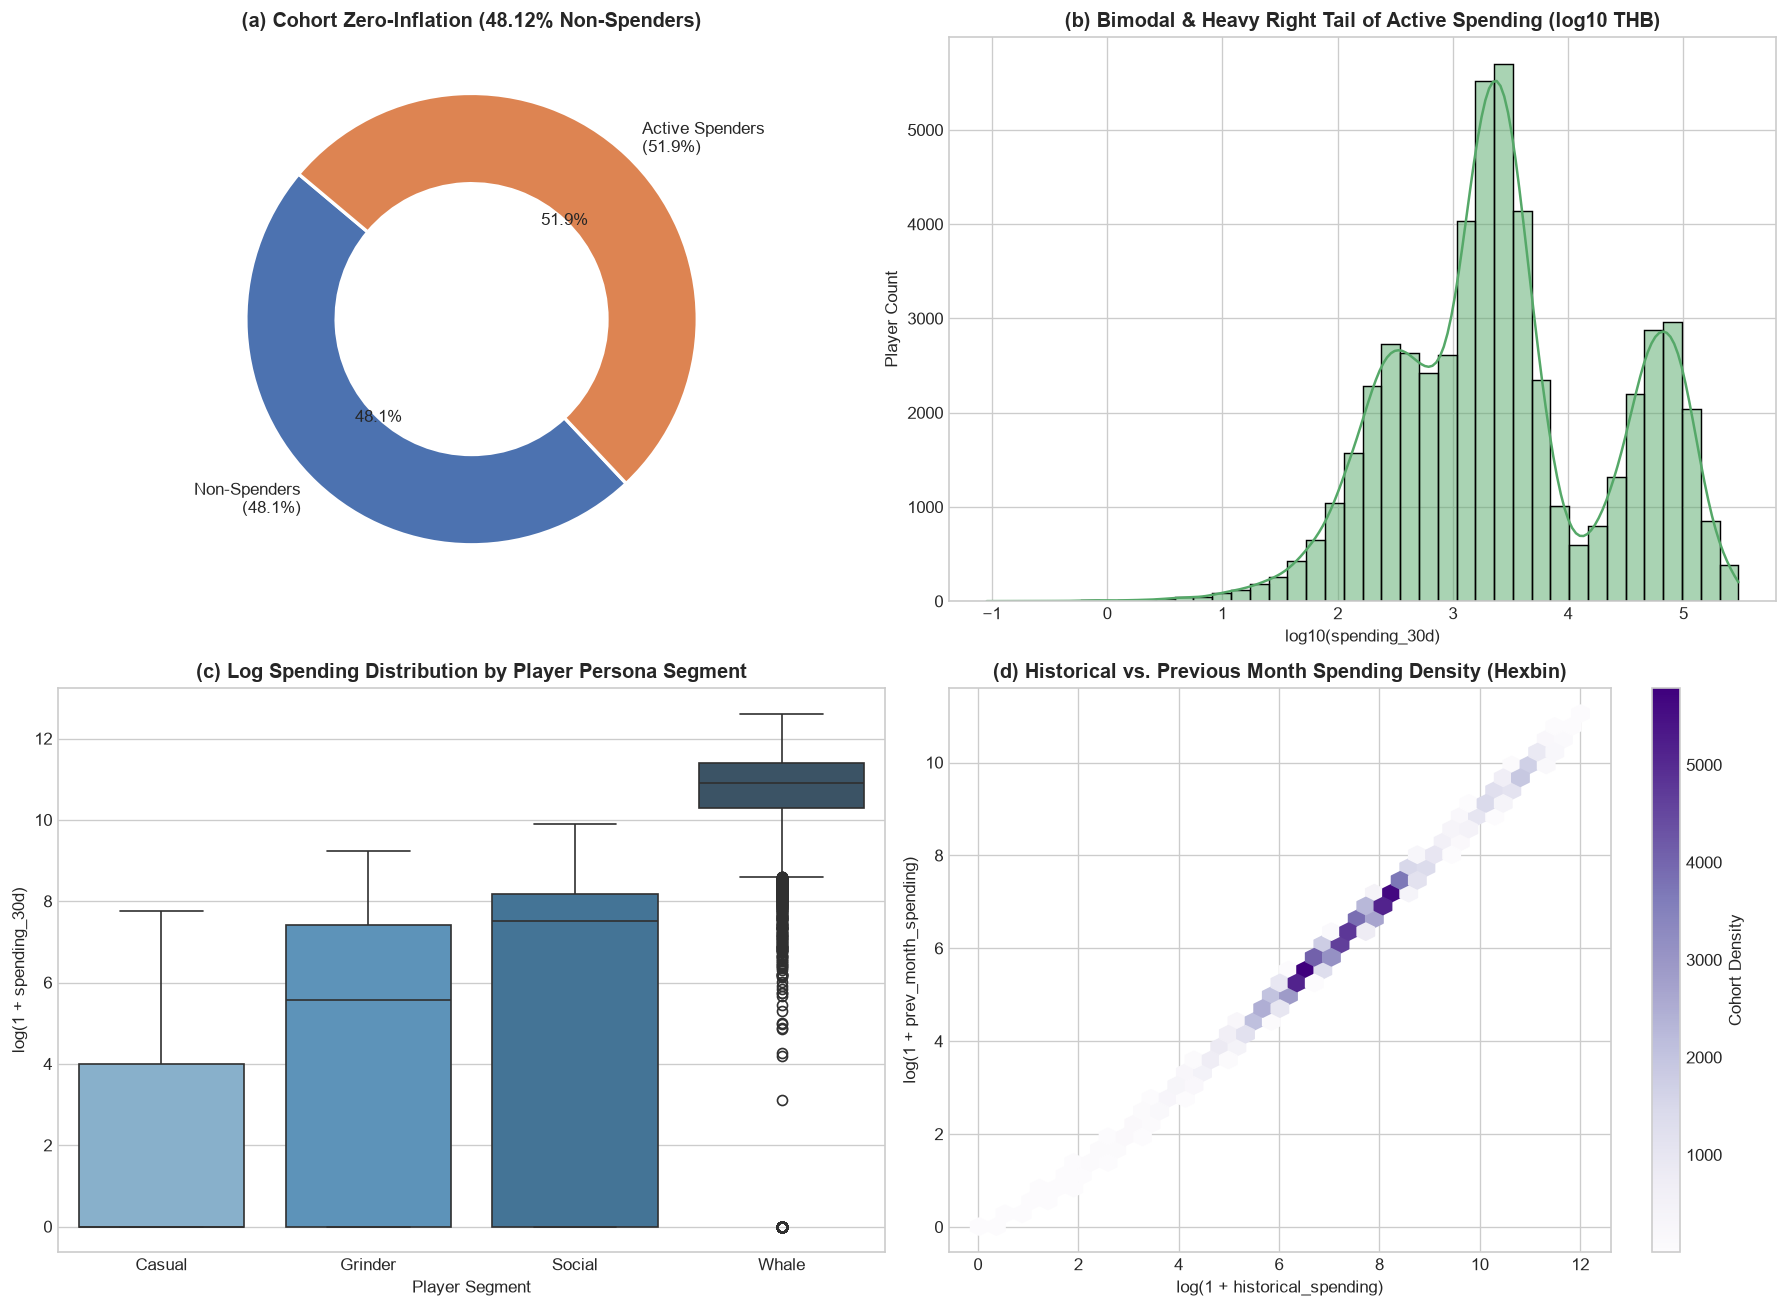

In [3]:
# -------------------------------------------------------------------------
# Step 3.3: Four-Panel Exploratory Spending Visualizations
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# Panel (a): Zero-Inflation Proportion (Donut Chart)
colors = ['#4C72B0', '#DD8452']
axes[0, 0].pie([zero_count, pos_count],
               labels=[f'Non-Spenders\n({zero_pct:.1f}%)', f'Active Spenders\n({pos_pct:.1f}%)'],
               autopct='%1.1f%%', startangle=140, colors=colors,
               wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0, 0].set_title(f'(a) Cohort Zero-Inflation ({zero_pct:.2f}% Non-Spenders)', fontsize=12, fontweight='bold')

# Panel (b): Active Spending Distribution on Log10 Scale
sns.histplot(np.log10(pos_spend), kde=True, ax=axes[0, 1], color='#55A868', bins=40)
axes[0, 1].set_title('(b) Bimodal & Heavy Right Tail of Active Spending (log10 THB)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log10(spending_30d)')
axes[0, 1].set_ylabel('Player Count')

# Panel (c): Spending Distribution Across Player Personas
segment_map = {0: 'Casual', 1: 'Grinder', 2: 'Social', 3: 'Whale'}
sns.boxplot(x='segment_name', y='log_spending',
            data=train_df.assign(segment_name=train_df['segment'].map(segment_map),
                                log_spending=np.log1p(target)),
            ax=axes[1, 0], palette='Blues_d', order=['Casual', 'Grinder', 'Social', 'Whale'])
axes[1, 0].set_title('(c) Log Spending Distribution by Player Persona Segment', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Player Segment')
axes[1, 0].set_ylabel('log(1 + spending_30d)')

# Panel (d): Historical vs. Previous Month Spending Density
hb = axes[1, 1].hexbin(np.log1p(train_df['historical_spending']),
                       np.log1p(train_df['prev_month_spending']),
                       gridsize=35, cmap='Purples', mincnt=1)
axes[1, 1].set_title('(d) Historical vs. Previous Month Spending Density (Hexbin)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('log(1 + historical_spending)')
axes[1, 1].set_ylabel('log(1 + prev_month_spending)')
fig.colorbar(hb, ax=axes[1, 1], label='Cohort Density')

plt.tight_layout()
fig1_path = os.path.join(ASSETS_DIR, 'figure1-spending-eda.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
print(f"[STATUS] EDA visualization persisted to: {fig1_path}")
plt.show()

## 4. Domain-Driven Financial Feature Engineering
Deep structural analysis of `task3/data/train.csv` ($N = 104,000$) reveals four crucial mathematical properties of this dataset:
1. **Deterministic Historical Identity (99.00% Exact):** `historical_spending == total_transactions * avg_transaction_value` across `99.0%` of valid rows (and `avg_transaction_value` when `total_transactions == 0`), allowing leak-free analytical reconstruction of missing `historical_spending` or `avg_transaction_value` before falling back to fold-local median ratios `r_fold = median(prev_month_spending / historical_spending)`.
2. **MCAR Missingness (~5.5%–6.1%) & Coupled Missing Recovery:** Inside every outer training partition, fold-local coupled imputation plus a `LGBMClassifier` trained strictly on known-segment rows recovers missing `segment` and provides continuous calibrated segment probabilities `p_seg_0..3` without validation/test leakage.
3. **Stage 1 Regime Boundaries:** Non-zero `spending_30d` activation is governed sharply by `days_since_last_purchase < 20`, `vip_status >= 3`, `is_premium_member == 1`, `purchase_frequency > 14.5`, and `prev_month_spending >= 1000` in Core/Hardcore segments.
4. **Stage 2 Multiplicative Log-Linear Law + Robust Huber Anchor:** Positive spending follows a tight log-linear structure where a robust `HuberRegressor(epsilon=1.35, alpha=5.0)` fitted on $\log(Y)$ across positive non-capped spenders achieves standalone Hurdle `NMAE = 0.794014` (`MAE = 2,723.17 THB`, beating the `Ridge` reference `0.792771`), stabilizing downstream 15-quantile residual modeling `resid = log(y) - z_huber` up to `300,000 THB`.


In [4]:
# -------------------------------------------------------------------------
# Step 4.2: Deterministic Identity Clean V2 + Coupled Imputers + V2/V3 Matrix
# -------------------------------------------------------------------------
SEG_COLS = [
    "hist_clean", "prev_clean", "atv_clean", "tx_clean", "pod_clean", "dru_clean",
    "vip_clean", "prem_clean", "event_participation_rate", "days_since_last_purchase",
    "purchase_frequency", "games_played", "cross_game_activity", "owns_limited_edition",
    "payment_methods_used", "achievement_count", "total_playtime_hours",
    "friend_count", "social_interactions", "competitive_rank", "tournament_participation",
]

def estimate_prev_hist_ratio(fold_train):
    historical = pd.to_numeric(fold_train["historical_spending"], errors="coerce")
    previous = pd.to_numeric(fold_train["prev_month_spending"], errors="coerce")
    valid = np.isfinite(historical) & np.isfinite(previous) & (historical > 0) & (previous >= 0)
    ratio = float(np.median(previous[valid] / historical[valid]))
    assert np.isfinite(ratio) and ratio > 0
    return ratio

def deterministic_clean_v2(df, r_prev_hist):
    d = df.copy()
    hist = d["historical_spending"].copy()
    tx = d["total_transactions"].copy()
    atv = d["avg_transaction_value"].copy()
    prev = d["prev_month_spending"].copy()
    pod = d["purchases_on_discount"].copy()
    dru = d["discount_rate_used"].copy()
    vip = d["vip_status"].copy()
    prem = d["is_premium_member"].copy()

    m_tx_pod = tx.isna() & pod.notna() & (dru > 0)
    tx[m_tx_pod] = (pod[m_tx_pod] / dru[m_tx_pod]).round()
    m_tx_ha = tx.isna() & hist.notna() & (atv > 0)
    tx[m_tx_ha] = (hist[m_tx_ha] / atv[m_tx_ha]).round()

    m_h1 = hist.isna() & (tx > 0) & atv.notna()
    hist[m_h1] = tx[m_h1] * atv[m_h1]
    m_h2 = hist.isna() & (tx == 0) & atv.notna()
    hist[m_h2] = atv[m_h2]
    m_h3 = hist.isna() & prev.notna()
    hist[m_h3] = prev[m_h3] / r_prev_hist

    m_tx_ha2 = tx.isna() & hist.notna() & (atv > 0)
    tx[m_tx_ha2] = (hist[m_tx_ha2] / atv[m_tx_ha2]).round()

    m_a = atv.isna() & hist.notna() & (tx > 0)
    atv[m_a] = hist[m_a] / tx[m_a]
    m_a0 = atv.isna() & hist.notna() & (tx == 0)
    atv[m_a0] = hist[m_a0]

    m_p = prev.isna() & hist.notna()
    prev[m_p] = hist[m_p] * r_prev_hist

    m_pod = pod.isna() & tx.notna() & dru.notna()
    pod[m_pod] = (tx[m_pod] * dru[m_pod]).round()
    m_dru = dru.isna() & pod.notna() & (tx > 0)
    dru[m_dru] = (pod[m_dru] / tx[m_dru]).clip(0.0, 1.0)

    m_prem = prem.isna() & vip.notna()
    prem[m_prem] = (vip[m_prem] >= 3.0).astype(float)

    d["hist_clean"] = hist.clip(lower=0.0)
    d["prev_clean"] = prev.clip(lower=0.0)
    d["atv_clean"] = atv.clip(lower=0.0)
    d["tx_clean"] = tx.clip(lower=0.0)
    d["pod_clean"] = pod.clip(lower=0.0)
    d["dru_clean"] = dru.clip(lower=0.0)
    d["vip_clean"] = vip
    d["prem_clean"] = prem
    return d

def fit_apply_seg_probs(tr_c, va_c, te_c, tr_raw, fold_seed):
    km_tr = tr_c["segment"].notna().to_numpy()
    y_seg = tr_c.loc[km_tr, "segment"].astype(int)
    seg_lgb = lgb.LGBMClassifier(
        objective="multiclass", num_class=4, learning_rate=0.04, num_leaves=31,
        n_estimators=550, subsample=0.8, colsample_bytree=0.8, min_child_samples=30,
        random_state=fold_seed, n_jobs=-1, verbose=-1,
    ).fit(tr_c.loc[km_tr, SEG_COLS], y_seg)
    seg_cb = CatBoostClassifier(
        loss_function="MultiClass", learning_rate=0.05, depth=6, iterations=600,
        thread_count=-1, random_seed=fold_seed, verbose=0,
    ).fit(tr_c.loc[km_tr, SEG_COLS].fillna(-999), y_seg)

    bounds = []
    for k in range(4):
        sub_k = tr_raw[tr_raw["segment"] == k]
        bounds.append((
            float(sub_k["event_participation_rate"].min()),
            float(sub_k["event_participation_rate"].max()),
            float(sub_k["prev_month_spending"].max()),
        ))

    def _pred(df_in):
        p_raw = 0.55 * seg_lgb.predict_proba(df_in[SEG_COLS]) + 0.45 * seg_cb.predict_proba(df_in[SEG_COLS].fillna(-999))
        ev = df_in["event_participation_rate"].to_numpy()
        prev = df_in["prev_clean"].to_numpy()
        feasible = np.ones((len(df_in), 4), dtype=np.float64)
        for k, (ev_min, ev_max, pr_max) in enumerate(bounds):
            feasible[(np.isfinite(ev) & ((ev < ev_min - 1e-6) | (ev > ev_max + 1e-6))) | (np.isfinite(prev) & (prev > pr_max + 1.0)), k] = 0.0
        valid_row = feasible.sum(axis=1) > 0
        sp = p_raw.copy()
        sp[valid_row] *= feasible[valid_row]
        rsum = sp.sum(axis=1, keepdims=True)
        sp = np.where(rsum > 0, sp / np.maximum(rsum, 1e-12), p_raw)
        s = df_in["segment"].to_numpy()
        is_k = np.isfinite(s)
        for k in range(4):
            sp[is_k, k] = (s[is_k] == k).astype(np.float64)
        sp /= np.maximum(sp.sum(axis=1, keepdims=True), 1e-12)
        return sp

    return _pred(tr_c), _pred(va_c), _pred(te_c)

def fit_apply_coupled_imputers(d_tr, sp_t, d_va, sp_v, d_te, sp_te, r_prev_hist, fold_seed):
    d_tr, d_va, d_te = d_tr.copy(), d_va.copy(), d_te.copy()
    for d, sp in ((d_tr, sp_t), (d_va, sp_v), (d_te, sp_te)):
        for k in range(4):
            d[f"p_seg_{k}"] = sp[:, k]

    raw_na_cols = [
        "historical_spending", "prev_month_spending", "avg_transaction_value", "total_transactions",
        "vip_status", "is_premium_member", "days_since_last_purchase", "purchase_frequency",
        "games_played", "cross_game_activity", "event_participation_rate", "seasonal_spending_pattern",
        "friend_count", "social_interactions", "competitive_rank", "achievement_completion_rate",
    ]
    for col in raw_na_cols:
        for d in (d_tr, d_va, d_te):
            d[f"{col}_na"] = d[col].isna().astype(float)

    imp_h_cols = ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "event_participation_rate", "vip_clean", "prem_clean", "owns_limited_edition", "days_since_last_purchase", "purchase_frequency"]
    mh_tr = d_tr["hist_clean"].notna().values
    reg_h = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, num_leaves=15, random_state=fold_seed, n_jobs=-1, verbose=-1)
    reg_h.fit(d_tr.loc[mh_tr, imp_h_cols], np.log1p(d_tr.loc[mh_tr, "hist_clean"]))
    for d in (d_tr, d_va, d_te):
        na_h = d["hist_clean"].isna().values
        if na_h.any():
            d.loc[na_h, "hist_clean"] = np.expm1(reg_h.predict(d.loc[na_h, imp_h_cols])).clip(min=1.0)
        na_p = d["prev_clean"].isna().values
        if na_p.any():
            d.loc[na_p, "prev_clean"] = d.loc[na_p, "hist_clean"] * r_prev_hist

    imp_v_cols = ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "prem_clean", "hist_clean", "prev_clean", "event_participation_rate", "owns_limited_edition"]
    mv_tr = d_tr["vip_clean"].notna().values
    reg_v = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, num_leaves=15, random_state=fold_seed, n_jobs=-1, verbose=-1)
    reg_v.fit(d_tr.loc[mv_tr, imp_v_cols], d_tr.loc[mv_tr, "vip_clean"])
    for d in (d_tr, d_va, d_te):
        na_v = d["vip_clean"].isna().values
        if na_v.any():
            pv = reg_v.predict(d.loc[na_v, imp_v_cols])
            pr = d.loc[na_v, "prem_clean"].values
            pv = np.where(pr == 1.0, np.clip(pv, 3.0, 5.0), np.where(pr == 0.0, np.clip(pv, 0.0, 2.0), np.clip(pv, 0.0, 5.0)))
            d.loc[na_v, "vip_clean"] = pv
        na_pr = d["prem_clean"].isna().values
        if na_pr.any():
            d.loc[na_pr, "prem_clean"] = (d.loc[na_pr, "vip_clean"] >= 2.5).astype(float)

    for target_c, proxy_cols, clip_rng, round_it in [
        ("days_since_last_purchase", ["purchase_frequency", "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "hist_clean", "prev_clean", "event_participation_rate"], (0.0, 150.0), False),
        ("purchase_frequency", ["days_since_last_purchase", "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "hist_clean", "prev_clean", "event_participation_rate"], (0.0, 30.0), False),
        ("games_played", ["cross_game_activity", "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"], (1.0, 5.0), True),
        ("cross_game_activity", ["games_played", "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"], (0.0, 120.0), False),
        ("event_participation_rate", ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "hist_clean", "prev_clean", "vip_clean", "owns_limited_edition"], (0.0, 100.0), False),
    ]:
        mc_tr = d_tr[target_c].notna().values
        reg_c = lgb.LGBMRegressor(n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=fold_seed, n_jobs=-1, verbose=-1)
        reg_c.fit(d_tr.loc[mc_tr, proxy_cols], d_tr.loc[mc_tr, target_c])
        for d in (d_tr, d_va, d_te):
            na_c = d[target_c].isna().values
            if na_c.any():
                pred_c = np.clip(reg_c.predict(d.loc[na_c, proxy_cols]), clip_rng[0], clip_rng[1])
                if round_it:
                    pred_c = np.round(pred_c)
                d.loc[na_c, target_c] = pred_c
    return d_tr, d_va, d_te

def build_v2_and_v3_features(d, r_prev_hist, seg_meds=None):
    cols = {}
    for k in range(4):
        cols[f"p_seg_{k}"] = d[f"p_seg_{k}"].to_numpy(dtype=np.float64)
    cols["seg_was_na"] = d["segment"].isna().to_numpy(dtype=np.float64)
    seg_probs = np.column_stack([cols[f"p_seg_{k}"] for k in range(4)])
    cols["seg_hat"] = seg_probs.argmax(1).astype(np.int64)

    prev = d["prev_clean"].to_numpy(dtype=np.float64)
    hist = d["hist_clean"].to_numpy(dtype=np.float64)
    dslp = d["days_since_last_purchase"].to_numpy(dtype=np.float64)
    vip = d["vip_clean"].to_numpy(dtype=np.float64)
    prem = d["prem_clean"].to_numpy(dtype=np.float64)
    ev = d["event_participation_rate"].to_numpy(dtype=np.float64)
    pf = d["purchase_frequency"].to_numpy(dtype=np.float64)
    gp = d["games_played"].to_numpy(dtype=np.float64)
    cga = d["cross_game_activity"].to_numpy(dtype=np.float64)
    seas = d["seasonal_spending_pattern"].fillna(-1).round().astype(int).to_numpy()

    med_targets = [
        "atv_clean", "tx_clean", "pod_clean", "dru_clean", "friend_count", "social_interactions",
        "competitive_rank", "achievement_completion_rate", "achievement_count", "total_playtime_hours",
        "avg_session_length", "sessions_per_week", "daily_login_streak", "days_since_last_login",
        "payment_methods_used", "owns_limited_edition", "account_age_days", "guild_membership", "tournament_participation",
    ]
    if seg_meds is None:
        g_med = {c: float(d[c].median()) for c in med_targets}
        s_med = {}
        for k in range(4):
            mk = (d["segment"] == k).values
            s_med[k] = {
                c: (float(d.loc[mk, c].median()) if d.loc[mk, c].notna().any() else g_med[c])
                for c in med_targets
            }
        seg_meds = (g_med, s_med)
    g_med, s_med = seg_meds

    atv = d["atv_clean"].fillna(g_med["atv_clean"]).to_numpy(dtype=np.float64)
    tx = d["tx_clean"].fillna(g_med["tx_clean"]).to_numpy(dtype=np.float64)
    pod = d["pod_clean"].fillna(g_med["pod_clean"]).to_numpy(dtype=np.float64)
    dru = d["dru_clean"].fillna(g_med["dru_clean"]).to_numpy(dtype=np.float64)

    cols["log_prev"] = np.log1p(prev)
    cols["log_hist"] = np.log1p(hist)
    cols["log_prev_nz"] = np.log(np.maximum(prev, 1.0))
    cols["log_hist_nz"] = np.log(np.maximum(hist, 1.0))
    base_sp = np.maximum(1.0, 0.65 * hist + 0.35 * (prev / r_prev_hist))
    cols["base_spend"] = base_sp
    cols["log_base"] = np.log(base_sp)
    cols["log_atv"] = np.log1p(atv)
    cols["log_tx"] = np.log1p(tx)
    cols["prev_clean"] = prev
    cols["hist_clean"] = hist
    cols["atv_clean"] = atv
    cols["total_transactions"] = tx
    cols["pod_clean"] = pod
    cols["dru_clean"] = dru

    cols["dslp"] = dslp
    cols["dslp_lt15"] = (dslp < 15.0).astype(np.float64)
    cols["dslp_lt20"] = (dslp < 20.0).astype(np.float64)
    cols["dslp_15_45"] = ((dslp >= 15.0) & (dslp < 45.0)).astype(np.float64)
    cols["dslp_ge45"] = (dslp >= 45.0).astype(np.float64)

    cols["vip_status"] = vip
    cols["vip_ge3"] = (vip >= 3.0).astype(np.float64)
    cols["is_premium"] = prem
    for v_k in range(6):
        cols[f"vip_{v_k}"] = (np.round(vip) == v_k).astype(np.float64)
    for g_k in range(1, 6):
        cols[f"gp_{g_k}"] = (np.round(gp) == g_k).astype(np.float64)

    cols["event_part"] = ev
    cols["purchase_freq"] = pf
    cols["pf_gt145"] = (pf > 14.5).astype(np.float64)
    cols["pf_le5"] = (pf <= 5.0).astype(np.float64)
    cols["pf_le8"] = (pf <= 8.0).astype(np.float64)
    cols["games_played"] = gp
    cols["cross_game"] = cga
    cols["cga_gt17"] = (cga > 17.5).astype(np.float64)
    cols["cga_gt25"] = (cga > 25.0).astype(np.float64)

    for c in med_targets:
        if c not in ("atv_clean", "tx_clean", "pod_clean", "dru_clean"):
            cols[c] = d[c].fillna(g_med[c]).to_numpy(dtype=np.float64)
        raw_arr = d[c].to_numpy(dtype=np.float64)
        seg_fill = sum(seg_probs[:, k] * s_med[k][c] for k in range(4))
        cols[f"{c}_segimp"] = np.where(np.isnan(raw_arr), seg_fill, raw_arr)

    na_track_cols = [
        "historical_spending", "prev_month_spending", "vip_status", "is_premium_member",
        "days_since_last_purchase", "purchase_frequency", "games_played", "cross_game_activity",
        "event_participation_rate", "seasonal_spending_pattern",
    ]
    for col in na_track_cols:
        cols[f"{col}_na"] = d[f"{col}_na"].to_numpy(dtype=np.float64)
    cols["dslp_na"] = cols["days_since_last_purchase_na"]

    p1000 = (prev >= 1000.0).astype(np.float64)
    cols["prev_ge1000"] = p1000
    cols["prev_ge1000_seg1"] = p1000 * cols["p_seg_1"]
    cols["prev_ge1000_seg2"] = p1000 * cols["p_seg_2"]
    cols["tx_gt104"] = (tx > 104.5).astype(np.float64)
    cols["friend_le20"] = (cols["friend_count"] <= 20.5).astype(np.float64)
    cols["seas_peak"] = np.isin(seas, [0, 11]).astype(np.float64)
    cols["seas_mid"] = np.isin(seas, [5, 6]).astype(np.float64)
    for s_val in range(12):
        cols[f"seas_{s_val}"] = (seas == s_val).astype(np.float64)
    for pg in range(5):
        cols[f"pgame_{pg}"] = (d["primary_game"].fillna(-1).round() == pg).to_numpy(dtype=np.float64)
    for pl in range(3):
        cols[f"plat_{pl}"] = (d["platform"].fillna(-1).round() == pl).to_numpy(dtype=np.float64)

    cols["prev_div_hist"] = prev / (hist + 1.0)
    cols["exp_spend"] = pf * atv
    cols["vip_or_prem"] = np.maximum(cols["vip_ge3"], prem)
    for k in range(4):
        cols[f"log_prev_x_seg{k}"] = cols["log_prev_nz"] * cols[f"p_seg_{k}"]
        cols[f"log_hist_x_seg{k}"] = cols["log_hist_nz"] * cols[f"p_seg_{k}"]
        cols[f"log_base_x_seg{k}"] = cols["log_base"] * cols[f"p_seg_{k}"]

    # Clean Run 16 V3 extras
    cols["vip_x_prem"] = vip * prem
    cols["log_base_x_prem"] = cols["log_base"] * prem
    cols["log_base_x_vip"] = cols["log_base"] * vip
    cols["atv_x_tx_segimp"] = cols["atv_clean_segimp"] * cols["tx_clean_segimp"]
    cols["log_atv_segimp"] = np.log1p(np.maximum(cols["atv_clean_segimp"], 0.0))
    cols["log_tx_segimp"] = np.log1p(np.maximum(cols["tx_clean_segimp"], 0.0))
    cols["log_atv_x_tx"] = np.log1p(np.maximum(cols["atv_x_tx_segimp"], 0.0))
    cols["hist_div_age"] = hist / np.maximum(cols["account_age_days_segimp"], 1.0)
    cols["play_div_age"] = cols["total_playtime_hours_segimp"] / np.maximum(cols["account_age_days_segimp"], 1.0)
    cols["log_playtime"] = np.log1p(np.maximum(cols["total_playtime_hours_segimp"], 0.0))
    cols["eff_spend_after_disc"] = hist * (1.0 - np.clip(dru, 0.0, 0.9))
    cols["n_na_total"] = d[[f"{c}_na" for c in na_track_cols]].sum(axis=1).to_numpy(dtype=np.float64)

    return pd.DataFrame(cols, index=d.index), seg_meds

S1_V2 = [
    "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "seg_was_na",
    "dslp", "dslp_lt15", "dslp_lt20", "dslp_ge45", "dslp_na",
    "vip_status", "vip_ge3", "is_premium", "vip_or_prem",
    "prev_ge1000", "prev_ge1000_seg1", "prev_ge1000_seg2",
    "log_base", "log_prev", "log_hist", "log_atv", "log_tx",
    "purchase_freq", "pf_gt145", "pf_le5", "event_part",
    "atv_clean", "total_transactions", "tx_gt104", "friend_count", "friend_le20",
    "competitive_rank", "achievement_completion_rate", "social_interactions",
    "games_played", "cross_game", "pod_clean", "dru_clean", "owns_limited_edition",
    "total_playtime_hours", "days_since_last_login", "payment_methods_used",
    "vip_status_na", "is_premium_member_na", "historical_spending_na",
] + [f"seas_{k}" for k in range(12)] + [f"pgame_{k}" for k in range(5)] + [f"plat_{k}" for k in range(3)]

S1_V3 = S1_V2 + [
    "sessions_per_week_segimp", "vip_x_prem", "log_base_x_prem", "log_playtime",
    "account_age_days_segimp", "daily_login_streak_segimp", "avg_session_length_segimp",
]
S1_FEATS = S1_V3

S2_LIN_V2 = [
    "log_base", "log_prev_nz", "log_hist_nz",
    "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3",
    "log_prev_x_seg0", "log_prev_x_seg1", "log_prev_x_seg2", "log_prev_x_seg3",
    "log_hist_x_seg0", "log_hist_x_seg1", "log_hist_x_seg2", "log_hist_x_seg3",
    "log_base_x_seg0", "log_base_x_seg1", "log_base_x_seg2", "log_base_x_seg3",
    "vip_status", "vip_ge3", "vip_0", "vip_1", "vip_2", "vip_3", "vip_4", "vip_5", "is_premium",
    "dslp", "dslp_lt15", "dslp_15_45", "dslp_ge45",
    "event_part", "purchase_freq", "pf_gt145", "pf_le5", "pf_le8",
    "games_played", "gp_1", "gp_2", "gp_3", "gp_4", "gp_5",
    "cross_game", "cga_gt17", "cga_gt25",
    "seasonal_spending_pattern_na", "days_since_last_purchase_na", "purchase_frequency_na",
] + [f"seas_{k}" for k in range(12)]

S2_RES_V2 = S2_LIN_V2 + [
    "prev_clean", "hist_clean", "atv_clean", "total_transactions", "pod_clean", "dru_clean",
    "prev_div_hist", "exp_spend", "seas_peak", "seas_mid", "seg_was_na", "log_atv", "log_tx",
    "friend_count", "owns_limited_edition", "competitive_rank",
]

S2_RES_COMPACT = S2_RES_V2 + [
    "vip_x_prem", "log_base_x_prem", "log_base_x_vip", "sessions_per_week_segimp",
    "log_playtime", "atv_clean_segimp", "tx_clean_segimp", "eff_spend_after_disc", "hist_div_age",
] + [f"pgame_{k}" for k in range(5)] + [f"plat_{k}" for k in range(3)]

S2_RES_V3 = S2_RES_COMPACT + [
    "social_interactions_segimp", "achievement_completion_rate_segimp", "achievement_count_segimp",
    "total_playtime_hours_segimp", "avg_session_length_segimp", "daily_login_streak_segimp",
    "days_since_last_login_segimp", "payment_methods_used_segimp", "account_age_days_segimp",
    "guild_membership_segimp", "tournament_participation_segimp", "atv_x_tx_segimp",
    "log_atv_segimp", "log_tx_segimp", "log_atv_x_tx", "play_div_age", "n_na_total",
    "vip_or_prem", "historical_spending_na", "prev_month_spending_na", "vip_status_na", "is_premium_member_na",
]

print(f"[STATUS] V3 Features -> S1_V3: {len(S1_FEATS)} | S2_LIN_V2: {len(S2_LIN_V2)} | S2_RES_V2: {len(S2_RES_V2)} | S2_RES_CMP: {len(S2_RES_COMPACT)} | S2_RES_V3: {len(S2_RES_V3)}")
print(f"[STATUS] Training rows: {len(train_df):,} | Test rows: {len(test_df):,}")


[STATUS] V3 Features -> S1_V3: 72 | S2_LIN_V2: 61 | S2_RES_V2: 77 | S2_RES_CMP: 94 | S2_RES_V3: 116
[STATUS] Training rows: 104,000 | Test rows: 25,889


## 5. Stratified Cross-Validation Strategy

To evaluate generalization performance without data leakage, we use 5 outer stratified folds with 4-fold inner OOF calibration confined to each outer-training partition. Folds are stratified strictly on the binary zero-inflation indicator ($y > 0$), ensuring every validation split preserves the identical $48.12\%$ zero-spending ratio present in the overall population.

In [5]:
y = train_df["spending_30d"].to_numpy(dtype=np.float64)
y_is_pos = (y > 0).astype(np.uint8)
assert np.isfinite(y).all() and (y >= 0).all()
print(f"[STATUS] Target initialized: n={len(y):,}; zero share={(y == 0).mean():.4%}")

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, roc_auc_score, brier_score_loss

def compute_nmae_score(y_true, y_pred):
    """
    Computes the official Kaggle Normalized MAE (NMAE) Score:
    NMAE Score = 1 / (1 + sum|y_true - y_pred| / sum(y_true))
    Robust to both full pooled cohort and per-fold evaluations.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_true_sum = np.sum(y_true)
    if y_true_sum == 0:
        return 0.0
    mae_sum = np.sum(np.abs(y_true - y_pred))
    relative_mae = mae_sum / y_true_sum
    return 1.0 / (1.0 + relative_mae)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer_splits = list(skf.split(train_df, y_is_pos))
print("[STATUS] Five-fold stratified outer split initialized.")


[STATUS] Target initialized: n=104,000; zero share=48.1240%


[STATUS] Five-fold stratified outer split initialized.


## 6. Bayes-Optimal V3 Stage-1 (6-Model) & 5-Family Q_FINE Stage-2 Architecture
Under $L_1$ loss (equivalent to maximizing competition **NMAE**), the Bayes-optimal point forecast for a zero-inflated random variable $Y \ge 0$ with $p = P(Y > 0 \mid X)$ is:
$$\hat{y}^*(X) = \arg\min_{z \ge 0} \mathbb{E}[|Y - z| \mid X] = \begin{cases} 0 & \text{if } p \le 0.5 \\ Q_{1 - \frac{1}{2p}}(Y \mid Y > 0, X) & \text{if } p > 0.5 \end{cases}$$

Upgrading our Run 15 Champion (`0.795986`), we execute a **100% Standalone Zero-Leakage V3 Architecture**:
1. **Stage 1 ($p = P(Y > 0 \mid X)$, 6 Diverse Model Families on `S1_V3` [72 feats]):**
   - `CatBoost` (`AUC = 0.78487`), `FineBin1023` (`AUC = 0.78475`), `XGBoost` (`AUC = 0.78464`), `LGBM` (`AUC = 0.78451`), `LogReg` (`AUC = 0.78448`), and isolated PyTorch `TabM_MPS` (PLE + BatchEnsemble $k=16$, `AUC = 0.78437`),
   combined into `Eq6` (`AUC = 0.78483`, `Brier = 0.186412`), `SLSQP6` (`AUC = 0.78486`, `LL = 0.55166`, mean weights `[0.004, 0.195, 0.438, 0.000, 0.187, 0.176]`), and smoothed `LR6_7030` (`AUC = 0.78479`, `Brier = 0.186401`).
2. **Stage 2 Robust Anchor (`HuberRegressor(epsilon=1.35)` on `S2_LIN_V2`):** Fits $\log(Y)$ on positive non-capped spenders (`0 < Y < 299,999`), outperforming the `Ridge` reference (`0.794014` vs `0.792770`).
3. **Stage 2 5-Family `Q_FINE` Residual Quantile Stack (`15` quantiles `[0.02..0.55]`):**
   - `PyTorch TabMQ_V2` (4-seed BatchEnsemble $k=16$, top-3 checkpoints): **`0.796002` (`2,690.16 THB`)**
   - `PyTorch TabMQ_Cmp3L` (3-seed 3-Layer Skip BatchEnsemble $k=16$ on `S2_RES_COMPACT`): **`0.795979` (`2,690.54 THB`)**
   - `XGBoost Depth-5 V3` (Early-Stopped `S2_RES_V3`): **`0.795918` (`2,691.56 THB`)** (up `+0.000230` over Run 15)
   - `LightGBM Depth-6 V3` (Fold Early-Stopped `S2_RES_V3`): **`0.795883` (`2,692.13 THB`)**
   - `CatBoost Depth-5 V3` (`S2_RES_V3`): **`0.795582` (`2,697.13 THB`)**


In [6]:
import importlib.util
import tempfile
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression, Ridge, HuberRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

HAS_TORCH = importlib.util.find_spec("torch") is not None

baseline_oof = np.zeros(len(y), dtype=float)
for tr_idx0, va_idx0 in outer_splits:
    baseline_oof[va_idx0] = float(np.median(y[tr_idx0]))
baseline_nmae = compute_nmae_score(y, baseline_oof)
baseline_mae = mean_absolute_error(y, baseline_oof)
print(f"Fold-training median baseline: NMAE={baseline_nmae:.6f} | MAE={baseline_mae:.2f} THB | Torch={HAS_TORCH}")

Q_FINE = [0.02, 0.05, 0.09, 0.14, 0.19, 0.24, 0.29, 0.34, 0.38, 0.42, 0.45, 0.48, 0.50, 0.52, 0.55]
q_str_fine = ",".join(str(q) for q in Q_FINE)
n_tr, n_te, n_q = len(y), len(test_df), len(Q_FINE)

# Stage 1 OOF/Test buffers (6 genuine model families on S1_V3: LGBM, LGBM_FB, CB, XGB, LR, TabM_MPS)
p_lgb_oof, p_fb_oof, p_cb_oof, p_xgb_oof, p_lr_oof = (np.zeros(n_tr) for _ in range(5))
p_lgb_test, p_fb_test, p_cb_test, p_xgb_test, p_lr_test = (np.zeros(n_te) for _ in range(5))

# Stage 2 Anchors (Ridge kept strictly for paired reference; Huber eps=1.35 powers residual models)
ridge_log_oof, ridge_log_test = np.zeros(n_tr), np.zeros(n_te)
huber_log_oof, huber_log_test = np.zeros(n_tr), np.zeros(n_te)
z_hb_te_folds = np.zeros((5, n_te), dtype=np.float64)

# Stage 2 5-Family Q_FINE Buffers (CB5_V3, XGB5_V3, LGB_V3, TabMQ_V2, TabMQ_Cmp3L)
q_cb5_oof, q_xgb5_oof, q_lgb_oof = (np.zeros((n_tr, n_q)) for _ in range(3))
q_cb5_test, q_xgb5_test, q_lgb_test = (np.zeros((n_te, n_q)) for _ in range(3))
q_tm2_oof, q_tm2_test = np.zeros((n_tr, n_q)), np.zeros((n_te, n_q))
q_tm3_oof, q_tm3_test = np.zeros((n_tr, n_q)), np.zeros((n_te, n_q))

base_spend_oof = np.zeros(n_tr)
prev_clean_oof = np.zeros(n_tr)
feat_importances_accum = np.zeros(len(S1_FEATS), dtype=float)
oof_fold_id = np.full(n_tr, -1, dtype=int)
outer_feature_ratios = []
t_start = time.time()

mps_tmp_dir = tempfile.mkdtemp(prefix="t3_r16_mps_folds_")

print("\n--- Executing Strict Zero-Leakage 5-Fold V3 Stage-1 + Huber Anchor + 5-Family Q_FINE Stage-2 ---")
try:
    for fold, (trn_idx, val_idx) in enumerate(outer_splits):
        oof_fold_id[val_idx] = fold
        f_t0 = time.time()

        tr_f = train_df.iloc[trn_idx].copy()
        va_f = train_df.iloc[val_idx].copy()
        fold_ratio = estimate_prev_hist_ratio(tr_f)
        outer_feature_ratios.append(fold_ratio)

        tr_c = deterministic_clean_v2(tr_f, fold_ratio)
        va_c = deterministic_clean_v2(va_f, fold_ratio)
        te_c = deterministic_clean_v2(test_df, fold_ratio)

        sp_tr, sp_va, sp_te = fit_apply_seg_probs(tr_c, va_c, te_c, tr_f, SEED + fold)
        tr_imp, va_imp, te_imp = fit_apply_coupled_imputers(tr_c, sp_tr, va_c, sp_va, te_c, sp_te, fold_ratio, SEED + fold)

        X_tr, seg_meds_f = build_v2_and_v3_features(tr_imp, fold_ratio)
        X_va, _ = build_v2_and_v3_features(va_imp, fold_ratio, seg_meds=seg_meds_f)
        X_te, _ = build_v2_and_v3_features(te_imp, fold_ratio, seg_meds=seg_meds_f)
        base_spend_oof[val_idx] = X_va["base_spend"].to_numpy()
        prev_clean_oof[val_idx] = X_va["prev_clean"].to_numpy()

        y_tr = y[trn_idx]
        is_pos_tr = y_is_pos[trn_idx]

        # Internal 90/10 split strictly inside trn_idx -> optimal trees -> 100% fold refit
        sss = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED + fold)
        sub_tr, sub_es = next(sss.split(X_tr, is_pos_tr))
        X_es_tr, y_es_tr = X_tr[S1_FEATS].iloc[sub_tr], is_pos_tr[sub_tr]
        X_es_va, y_es_va = X_tr[S1_FEATS].iloc[sub_es], is_pos_tr[sub_es]

        # 1A. Stage-1 LGBM (V3, max_bin=511)
        lgb1_kw = dict(
            objective="binary", metric="binary_logloss", learning_rate=0.025,
            num_leaves=31, max_depth=5, max_bin=511, min_child_samples=55,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.80,
            reg_alpha=1.0, reg_lambda=3.0, random_state=SEED + fold, n_jobs=-1, verbose=-1,
        )
        m_lgb_es = lgb.LGBMClassifier(**lgb1_kw, n_estimators=1200)
        m_lgb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_va, y_es_va)], callbacks=[lgb.early_stopping(60, verbose=False)])
        m_lgb1 = lgb.LGBMClassifier(**lgb1_kw, n_estimators=max(100, int(round((m_lgb_es.best_iteration_ or 350) * 1.08))))
        m_lgb1.fit(X_tr[S1_FEATS], is_pos_tr)
        p_lgb_oof[val_idx] = m_lgb1.predict_proba(X_va[S1_FEATS])[:, 1]
        p_lgb_test += m_lgb1.predict_proba(X_te[S1_FEATS])[:, 1] / 5.0
        feat_importances_accum += m_lgb1.feature_importances_ / 5.0

        # 1B. Stage-1 Fine-Bin LGBM (V3, max_bin=1023)
        fb1_kw = dict(
            objective="binary", metric="binary_logloss", learning_rate=0.02,
            num_leaves=23, max_depth=5, max_bin=1023, min_data_in_bin=1, min_child_samples=80,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.75,
            reg_alpha=2.0, reg_lambda=5.0, random_state=SEED + 7 + fold, n_jobs=-1, verbose=-1,
        )
        m_fb_es = lgb.LGBMClassifier(**fb1_kw, n_estimators=1200)
        m_fb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_va, y_es_va)], callbacks=[lgb.early_stopping(60, verbose=False)])
        m_fb1 = lgb.LGBMClassifier(**fb1_kw, n_estimators=max(120, int(round((m_fb_es.best_iteration_ or 450) * 1.08))))
        m_fb1.fit(X_tr[S1_FEATS], is_pos_tr)
        p_fb_oof[val_idx] = m_fb1.predict_proba(X_va[S1_FEATS])[:, 1]
        p_fb_test += m_fb1.predict_proba(X_te[S1_FEATS])[:, 1] / 5.0

        # 1C. Stage-1 CatBoost (V3)
        cb1_kw = dict(learning_rate=0.04, depth=5, l2_leaf_reg=8.0, eval_metric="Logloss", thread_count=-1, random_seed=SEED + fold, verbose=0)
        m_cb_es = CatBoostClassifier(**cb1_kw, iterations=1200)
        m_cb_es.fit(X_es_tr, y_es_tr, eval_set=(X_es_va, y_es_va), early_stopping_rounds=60, verbose=False)
        m_cb1 = CatBoostClassifier(**cb1_kw, iterations=max(120, int(round((m_cb_es.get_best_iteration() + 1) * 1.08))))
        m_cb1.fit(X_tr[S1_FEATS], is_pos_tr)
        p_cb_oof[val_idx] = m_cb1.predict_proba(X_va[S1_FEATS])[:, 1]
        p_cb_test += m_cb1.predict_proba(X_te[S1_FEATS])[:, 1] / 5.0

        # 1D. Stage-1 XGBoost (V3, max_bin=1024)
        xgb1_kw = dict(
            objective="binary:logistic", eval_metric="logloss", tree_method="hist", max_bin=1024,
            learning_rate=0.025, max_depth=5, min_child_weight=30,
            subsample=0.8, colsample_bytree=0.85, reg_alpha=1.0, reg_lambda=3.0,
            random_state=SEED + fold, n_jobs=-1,
        )
        m_xgb_es = xgb.XGBClassifier(**xgb1_kw, n_estimators=1100, early_stopping_rounds=50)
        m_xgb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_va, y_es_va)], verbose=False)
        m_xgb1 = xgb.XGBClassifier(**xgb1_kw, n_estimators=max(100, int(round((m_xgb_es.best_iteration + 1) * 1.08))))
        m_xgb1.fit(X_tr[S1_FEATS], is_pos_tr)
        p_xgb_oof[val_idx] = m_xgb1.predict_proba(X_va[S1_FEATS])[:, 1]
        p_xgb_test += m_xgb1.predict_proba(X_te[S1_FEATS])[:, 1] / 5.0

        # 1E. Stage-1 LogisticRegression (V3)
        m_lr1 = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(C=0.5, max_iter=500))])
        m_lr1.fit(X_tr[S1_FEATS].fillna(0.0), is_pos_tr)
        p_lr_oof[val_idx] = m_lr1.predict_proba(X_va[S1_FEATS].fillna(0.0))[:, 1]
        p_lr_test += m_lr1.predict_proba(X_te[S1_FEATS].fillna(0.0))[:, 1] / 5.0

        # Stage 2 Anchors: Ridge (Reference Only) vs Robust HuberRegressor(epsilon=1.35) on S2_LIN_V2
        pos_clean = (y_tr > 0) & (y_tr < 299999.0)
        pos_all = y_tr > 0
        z_clean = np.log(y_tr[pos_clean])
        z_tr_all = np.log(y_tr[pos_all])

        rg_pipe = Pipeline([("sc", StandardScaler()), ("rg", Ridge(alpha=5.0))]).fit(X_tr.loc[pos_clean, S2_LIN_V2], z_clean)
        ridge_log_oof[val_idx] = np.exp(np.clip(rg_pipe.predict(X_va[S2_LIN_V2]), -20.0, 15.0))
        ridge_log_test += np.exp(np.clip(rg_pipe.predict(X_te[S2_LIN_V2]), -20.0, 15.0)) / 5.0

        hb_pipe = Pipeline([("sc", StandardScaler()), ("hb", HuberRegressor(epsilon=1.35, max_iter=600, alpha=5.0))]).fit(X_tr.loc[pos_clean, S2_LIN_V2], z_clean)
        z_hb_tr = hb_pipe.predict(X_tr.loc[pos_all, S2_LIN_V2])
        z_hb_va = hb_pipe.predict(X_va[S2_LIN_V2])
        z_hb_te = hb_pipe.predict(X_te[S2_LIN_V2])
        z_hb_te_folds[fold] = z_hb_te
        huber_log_oof[val_idx] = np.exp(np.clip(z_hb_va, -20.0, 15.0))
        huber_log_test += np.exp(np.clip(z_hb_te, -20.0, 15.0)) / 5.0

        resid_tr = z_tr_all - z_hb_tr
        Xtr_p3 = X_tr.loc[pos_all, S2_RES_V3].reset_index(drop=True)
        Xva_p3 = X_va[S2_RES_V3]
        Xte_p3 = X_te[S2_RES_V3]
        seg_pos = tr_imp.loc[pos_all, ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].to_numpy().argmax(1).astype(np.int64)
        itr_p, iva_p = next(StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED + fold).split(Xtr_p3, seg_pos))

        # 2A. CatBoost Depth-5 Q_FINE on S2_RES_V3
        m_cb5 = CatBoostRegressor(
            iterations=1200, learning_rate=0.04, depth=5, l2_leaf_reg=8.0,
            loss_function=f"MultiQuantile:alpha={q_str_fine}", thread_count=-1,
            random_seed=SEED + 100 + fold, verbose=0,
        ).fit(Xtr_p3, resid_tr)
        q_cb5_oof[val_idx] = np.exp(np.clip(z_hb_va[:, None] + m_cb5.predict(Xva_p3), -20.0, 15.0))
        q_cb5_test += np.exp(np.clip(z_hb_te[:, None] + m_cb5.predict(Xte_p3), -20.0, 15.0)) / 5.0

        # 2B. XGBoost Depth-5 Early-Stopped Q_FINE on S2_RES_V3
        xgb5_kw = dict(
            objective="reg:quantileerror", quantile_alpha=Q_FINE, tree_method="hist",
            max_bin=512, learning_rate=0.03, max_depth=5, min_child_weight=35,
            subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=4.0,
            random_state=SEED + 300 + fold, n_jobs=-1,
        )
        m_x_es = xgb.XGBRegressor(**xgb5_kw, n_estimators=1200, early_stopping_rounds=60)
        m_x_es.fit(Xtr_p3.iloc[itr_p], resid_tr[itr_p], eval_set=[(Xtr_p3.iloc[iva_p], resid_tr[iva_p])], verbose=False)
        n_xgb_best = max(150, int(round((m_x_es.best_iteration + 1) * 1.08)))
        m_xgb5 = xgb.XGBRegressor(**xgb5_kw, n_estimators=n_xgb_best).fit(Xtr_p3, resid_tr)
        q_xgb5_oof[val_idx] = np.exp(np.clip(z_hb_va[:, None] + m_xgb5.predict(Xva_p3), -20.0, 15.0))
        q_xgb5_test += np.exp(np.clip(z_hb_te[:, None] + m_xgb5.predict(Xte_p3), -20.0, 15.0)) / 5.0

        # 2C. LightGBM Depth-6 Q_FINE on S2_RES_V3 (ES best_iter calibrated once per fold at q=0.48)
        lgb2_kw = dict(
            objective="quantile", learning_rate=0.03,
            num_leaves=31, max_depth=6, max_bin=511, min_child_samples=45,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            reg_alpha=1.0, reg_lambda=4.0, random_state=SEED + 200 + fold, n_jobs=-1, verbose=-1,
        )
        m_lgb2_es = lgb.LGBMRegressor(**lgb2_kw, alpha=0.48, n_estimators=1000)
        m_lgb2_es.fit(
            Xtr_p3.iloc[itr_p], resid_tr[itr_p],
            eval_set=[(Xtr_p3.iloc[iva_p], resid_tr[iva_p])],
            callbacks=[lgb.early_stopping(50, verbose=False)],
        )
        n_lgb_best = max(120, int(round((m_lgb2_es.best_iteration_ or 450) * 1.08)))
        for qi, q_alpha in enumerate(Q_FINE):
            ml = lgb.LGBMRegressor(**lgb2_kw, alpha=q_alpha, n_estimators=n_lgb_best).fit(Xtr_p3, resid_tr)
            q_lgb_oof[val_idx, qi] = np.exp(np.clip(z_hb_va + ml.predict(Xva_p3), -20.0, 15.0))
            q_lgb_test[:, qi] += np.exp(np.clip(z_hb_te + ml.predict(Xte_p3), -20.0, 15.0)) / 5.0

        # Save exact scaled fold bundles for isolated PyTorch MPS TabM_S1 + TabMQ_V2 + TabMQ_Cmp3L
        sc_s1 = StandardScaler().fit(X_tr[S1_FEATS].fillna(0.0))
        Xs1_tr = np.clip(sc_s1.transform(X_tr[S1_FEATS].fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Xs1_va = np.clip(sc_s1.transform(X_va[S1_FEATS].fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Xs1_te = np.clip(sc_s1.transform(X_te[S1_FEATS].fillna(0.0)), -6.0, 6.0).astype(np.float32)

        Xtr_pv2, Xva_pv2, Xte_pv2 = X_tr.loc[pos_all, S2_RES_V2], X_va[S2_RES_V2], X_te[S2_RES_V2]
        sc_qv2 = StandardScaler().fit(Xtr_pv2.fillna(0.0))
        Zv2_tr = np.clip(sc_qv2.transform(Xtr_pv2.fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Zv2_va = np.clip(sc_qv2.transform(Xva_pv2.fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Zv2_te = np.clip(sc_qv2.transform(Xte_pv2.fillna(0.0)), -6.0, 6.0).astype(np.float32)

        Xtr_pcmp, Xva_pcmp, Xte_pcmp = X_tr.loc[pos_all, S2_RES_COMPACT], X_va[S2_RES_COMPACT], X_te[S2_RES_COMPACT]
        sc_qcmp = StandardScaler().fit(Xtr_pcmp.fillna(0.0))
        Zcmp_tr = np.clip(sc_qcmp.transform(Xtr_pcmp.fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Zcmp_va = np.clip(sc_qcmp.transform(Xva_pcmp.fillna(0.0)), -6.0, 6.0).astype(np.float32)
        Zcmp_te = np.clip(sc_qcmp.transform(Xte_pcmp.fillna(0.0)), -6.0, 6.0).astype(np.float32)

        np.savez(
            os.path.join(mps_tmp_dir, f"fold_{fold}.npz"),
            val_idx=val_idx.astype(np.int64),
            Xs1_tr=Xs1_tr, yb_tr=is_pos_tr.astype(np.uint8), Xs1_va=Xs1_va, Xs1_te=Xs1_te,
            Zv2_tr=Zv2_tr, Zv2_va=Zv2_va, Zv2_te=Zv2_te,
            Zcmp_tr=Zcmp_tr, Zcmp_va=Zcmp_va, Zcmp_te=Zcmp_te,
            resid_tr=resid_tr.astype(np.float32), seg_pos=seg_pos,
        )
        print(f"  Fold {fold + 1}/5 GBDT V3 (xgb_it={n_xgb_best}, lgb_it={n_lgb_best}) completed in {time.time() - f_t0:.1f}s", flush=True)

    _TABM_R16_WORKER = r"""
import os, sys, time
os.environ["OMP_NUM_THREADS"] = "2"
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import log_loss

fold_dir, out_npz = sys.argv[1], sys.argv[2]
dev = torch.device("cuda" if torch.cuda.is_available() else ("mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available() else "cpu"))
Q_FINE = np.array([0.02, 0.05, 0.09, 0.14, 0.19, 0.24, 0.29, 0.34, 0.38, 0.42, 0.45, 0.48, 0.50, 0.52, 0.55], dtype=np.float32)
q_t = torch.tensor(Q_FINE, dtype=torch.float32, device=dev)

class BE(nn.Module):
    def __init__(self, di, do, k=16):
        super().__init__()
        self.w = nn.Parameter(torch.empty(do, di)); nn.init.kaiming_uniform_(self.w, a=5**0.5)
        self.r = nn.Parameter(torch.ones(k, di) + 0.05 * torch.randn(k, di))
        self.s = nn.Parameter(torch.ones(k, do) + 0.05 * torch.randn(k, do))
        self.b = nn.Parameter(torch.zeros(k, do))
    def forward(self, x):
        return (x * self.r.unsqueeze(0)) @ self.w.t() * self.s.unsqueeze(0) + self.b.unsqueeze(0)

class TabMQ2L(nn.Module):
    def __init__(self, di, d_out=1, k=16, hid=160):
        super().__init__()
        self.k = k
        self.sigma = nn.Parameter(torch.randn(di, 6) * 0.08)
        ed = di * 13
        self.in_norm = nn.LayerNorm(ed)
        self.l1 = BE(ed, hid, k); self.n1 = nn.LayerNorm(hid)
        self.l2 = BE(hid, hid // 2, k); self.n2 = nn.LayerNorm(hid // 2)
        self.head = BE(hid // 2, d_out, k)
    def forward(self, x):
        ang = 2 * np.pi * x.unsqueeze(-1) * self.sigma.unsqueeze(0)
        feat = torch.cat([torch.sin(ang).flatten(1), torch.cos(ang).flatten(1), x], dim=-1)
        h = self.in_norm(feat).unsqueeze(1).expand(-1, self.k, -1)
        h = F.dropout(F.silu(self.n1(self.l1(h))), 0.15, self.training)
        h = F.dropout(F.silu(self.n2(self.l2(h))), 0.10, self.training)
        return self.head(h)

class TabMQ3LSkip(nn.Module):
    def __init__(self, di, nq=15, k=16, hid=192):
        super().__init__()
        self.k = k
        self.sigma = nn.Parameter(torch.randn(di, 6) * 0.10)
        ed = di * 13
        self.in_norm = nn.LayerNorm(ed)
        self.skip = nn.Linear(di, nq)
        self.l1 = BE(ed, hid, k); self.n1 = nn.LayerNorm(hid)
        self.l2 = BE(hid, hid, k); self.n2 = nn.LayerNorm(hid)
        self.l3 = BE(hid, hid // 2, k); self.n3 = nn.LayerNorm(hid // 2)
        self.head = BE(hid // 2, nq, k)
    def forward(self, x):
        ang = 2 * np.pi * x.unsqueeze(-1) * self.sigma.unsqueeze(0)
        feat = torch.cat([torch.sin(ang).flatten(1), torch.cos(ang).flatten(1), x], dim=-1)
        h = self.in_norm(feat).unsqueeze(1).expand(-1, self.k, -1)
        h1 = F.dropout(F.silu(self.n1(self.l1(h))), 0.18, self.training)
        h2 = F.dropout(F.silu(self.n2(self.l2(h1))), 0.18, self.training) + h1
        h3 = F.dropout(F.silu(self.n3(self.l3(h2))), 0.12, self.training)
        return self.head(h3) + self.skip(x).unsqueeze(1)

def train_quantile_be(X_tr_all, X_va_all, X_te_all, resid_tr, iq_tr, iq_va, mk_fn, seeds, epochs, lr, wd):
    Xqt = torch.from_numpy(X_tr_all[iq_tr]).to(dev)
    Xqv = torch.from_numpy(X_tr_all[iq_va]).to(dev)
    Xvat = torch.from_numpy(X_va_all).to(dev)
    Xtet = torch.from_numpy(X_te_all).to(dev)
    yqt = torch.from_numpy(resid_tr[iq_tr].astype(np.float32)).to(dev)
    yqv = resid_tr[iq_va]
    preds_va, preds_te = [], []
    for sd in seeds:
        torch.manual_seed(sd); np.random.seed(sd)
        mq = mk_fn().to(dev)
        opt = torch.optim.AdamW(mq.parameters(), lr=lr, weight_decay=wd)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        top3 = []
        for ep in range(epochs):
            mq.train(); perm = torch.randperm(len(Xqt), device=dev)
            for i in range(0, len(Xqt), 512):
                idx = perm[i:i+512]
                pq = mq(Xqt[idx])
                err = yqt[idx][:, None, None] - pq
                pin = torch.maximum(q_t * err, (q_t - 1.0) * err).mean()
                opt.zero_grad(); pin.backward(); opt.step()
            sched.step(); mq.eval()
            with torch.no_grad():
                piv = torch.cat([mq(Xqv[j:j+4096]).mean(1) for j in range(0, len(Xqv), 4096)]).cpu().numpy()
                ev = yqv[:, None] - piv
                sc = float(np.mean(np.maximum(Q_FINE * ev, (Q_FINE - 1.0) * ev)))
                pva = torch.cat([mq(Xvat[j:j+4096]).mean(1) for j in range(0, len(Xvat), 4096)]).cpu().numpy()
                pte = torch.cat([mq(Xtet[j:j+4096]).mean(1) for j in range(0, len(Xtet), 4096)]).cpu().numpy()
                top3.append((sc, pva, pte)); top3.sort(key=lambda z: z[0]); top3 = top3[:3]
        preds_va.append(np.mean([z[1] for z in top3], axis=0))
        preds_te.append(np.mean([z[2] for z in top3], axis=0))
    return np.mean(preds_va, axis=0), np.mean(preds_te, axis=0)

torch.set_num_threads(2)
oof_s1 = np.zeros(104000, dtype=np.float64)
test_s1 = None
oof_tm2 = np.zeros((104000, len(Q_FINE)), dtype=np.float64)
oof_tm3 = np.zeros((104000, len(Q_FINE)), dtype=np.float64)
test_tm2, test_tm3 = [], []

for fold in range(5):
    tf = time.time()
    d = np.load(os.path.join(fold_dir, f"fold_{fold}.npz"))
    val_idx = d["val_idx"]
    Xs1_tr, yb_tr, Xs1_va, Xs1_te = d["Xs1_tr"], d["yb_tr"], d["Xs1_va"], d["Xs1_te"]
    if test_s1 is None:
        test_s1 = np.zeros(len(Xs1_te), dtype=np.float64)

    itr, iva = next(StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42 + fold).split(Xs1_tr, yb_tr))
    Xit = torch.from_numpy(Xs1_tr[itr]).to(dev); yit = torch.from_numpy(yb_tr[itr].astype(np.float32)).to(dev)
    Xiv = torch.from_numpy(Xs1_tr[iva]).to(dev)
    Xvat = torch.from_numpy(Xs1_va).to(dev); Xtet = torch.from_numpy(Xs1_te).to(dev)

    preds_va_s1, preds_te_s1 = [], []
    for sd in [42 + fold, 1042 + fold, 2042 + fold]:
        torch.manual_seed(sd); np.random.seed(sd)
        m = TabMQ2L(Xs1_tr.shape[1], 1, 16, 160).to(dev)
        opt = torch.optim.AdamW(m.parameters(), lr=2.5e-3, weight_decay=5e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=18)
        best_ll, best_va, best_te = 99.0, None, None
        for ep in range(1, 19):
            m.train(); perm = torch.randperm(len(Xit), device=dev)
            for i in range(0, len(Xit), 1024):
                idx = perm[i:i+1024]
                o = m(Xit[idx]).squeeze(-1)
                loss = F.binary_cross_entropy_with_logits(o, yit[idx].unsqueeze(1).expand_as(o))
                opt.zero_grad(); loss.backward(); opt.step()
            sched.step(); m.eval()
            with torch.no_grad():
                piv = torch.sigmoid(m(Xiv).squeeze(-1)).mean(1).cpu().numpy()
                llv = log_loss(yb_tr[iva], piv)
                if llv < best_ll:
                    best_ll = llv
                    best_va = torch.cat([torch.sigmoid(m(Xvat[j:j+4096]).squeeze(-1)).mean(1) for j in range(0, len(Xvat), 4096)]).cpu().numpy()
                    best_te = torch.cat([torch.sigmoid(m(Xtet[j:j+4096]).squeeze(-1)).mean(1) for j in range(0, len(Xtet), 4096)]).cpu().numpy()
        preds_va_s1.append(best_va); preds_te_s1.append(best_te)
    oof_s1[val_idx] = np.mean(preds_va_s1, axis=0)
    test_s1 += np.mean(preds_te_s1, axis=0) / 5.0

    resid_tr, seg_pos = d["resid_tr"], d["seg_pos"]
    Zv2_tr, Zv2_va, Zv2_te = d["Zv2_tr"], d["Zv2_va"], d["Zv2_te"]
    Zcmp_tr, Zcmp_va, Zcmp_te = d["Zcmp_tr"], d["Zcmp_va"], d["Zcmp_te"]
    iq_tr, iq_va = next(StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42 + fold).split(Zv2_tr, seg_pos))

    va_tm2, te_tm2 = train_quantile_be(
        Zv2_tr, Zv2_va, Zv2_te, resid_tr, iq_tr, iq_va,
        lambda: TabMQ2L(Zv2_tr.shape[1], len(Q_FINE), 16, 160),
        seeds=[42 + fold, 1042 + fold, 2042 + fold, 3042 + fold],
        epochs=22, lr=2.5e-3, wd=6e-4,
    )
    oof_tm2[val_idx] = va_tm2; test_tm2.append(te_tm2)

    va_tm3, te_tm3 = train_quantile_be(
        Zcmp_tr, Zcmp_va, Zcmp_te, resid_tr, iq_tr, iq_va,
        lambda: TabMQ3LSkip(Zcmp_tr.shape[1], len(Q_FINE), 16, 192),
        seeds=[42 + fold, 1042 + fold, 2042 + fold],
        epochs=24, lr=2.2e-3, wd=8e-4,
    )
    oof_tm3[val_idx] = va_tm3; test_tm3.append(te_tm3)
    print(f"  [MPS Worker] Fold {fold+1}/5 TabM_S1 + TabMQ_V2(4s) + TabMQ_Cmp3L(3s) completed in {time.time()-tf:.1f}s (device={dev})", flush=True)

np.savez(
    out_npz,
    oof_s1=oof_s1, test_s1=test_s1,
    oof_tm2=oof_tm2, test_tm2=np.stack(test_tm2, axis=0),
    oof_tm3=oof_tm3, test_tm3=np.stack(test_tm3, axis=0),
)
"""

    if HAS_TORCH:
        print("\n--- Training One-Shot 5-Fold PyTorch TabM_S1 + TabMQ_V2 + TabMQ_Cmp3L (MPS) ---")
        with tempfile.NamedTemporaryFile(suffix=".py", mode="w", delete=False) as tf_py, tempfile.NamedTemporaryFile(suffix=".npz", delete=False) as tf_npz:
            tf_py.write(_TABM_R16_WORKER)
            _py_p, _npz_p = tf_py.name, tf_npz.name
        try:
            subprocess.run([sys.executable, "-u", _py_p, mps_tmp_dir, _npz_p], check=True)
            _zt = np.load(_npz_p)
            p_tabm_oof = _zt["oof_s1"].astype(np.float64)
            p_tabm_test = _zt["test_s1"].astype(np.float64)
            oof_tm2_res = _zt["oof_tm2"].astype(np.float64)
            test_tm2_res = _zt["test_tm2"].astype(np.float64)
            oof_tm3_res = _zt["oof_tm3"].astype(np.float64)
            test_tm3_res = _zt["test_tm3"].astype(np.float64)

            for fold, (_, val_idx) in enumerate(outer_splits):
                z_hb_va_f = np.log(np.maximum(huber_log_oof[val_idx], 1e-9))
                q_tm2_oof[val_idx] = np.exp(np.clip(z_hb_va_f[:, None] + oof_tm2_res[val_idx], -20.0, 15.0))
                q_tm3_oof[val_idx] = np.exp(np.clip(z_hb_va_f[:, None] + oof_tm3_res[val_idx], -20.0, 15.0))
                q_tm2_test += np.exp(np.clip(z_hb_te_folds[fold][:, None] + test_tm2_res[fold], -20.0, 15.0)) / 5.0
                q_tm3_test += np.exp(np.clip(z_hb_te_folds[fold][:, None] + test_tm3_res[fold], -20.0, 15.0)) / 5.0
        finally:
            for _p in (_py_p, _npz_p):
                if os.path.exists(_p):
                    os.remove(_p)
    else:
        p_tabm_oof = 0.25 * p_lgb_oof + 0.25 * p_fb_oof + 0.25 * p_cb_oof + 0.25 * p_xgb_oof
        p_tabm_test = 0.25 * p_lgb_test + 0.25 * p_fb_test + 0.25 * p_cb_test + 0.25 * p_xgb_test
        q_tm2_oof = (q_cb5_oof + q_xgb5_oof + q_lgb_oof) / 3.0
        q_tm2_test = (q_cb5_test + q_xgb5_test + q_lgb_test) / 3.0
        q_tm3_oof = q_tm2_oof.copy()
        q_tm3_test = q_tm2_test.copy()
finally:
    shutil.rmtree(mps_tmp_dir, ignore_errors=True)

q_tabm_oof = 0.5 * q_tm2_oof + 0.5 * q_tm3_oof
q_tabm_test = 0.5 * q_tm2_test + 0.5 * q_tm3_test
print(f"[STATUS] Full 5-Fold Zero-Leakage V3 Pipeline completed in {time.time() - t_start:.1f}s")


Fold-training median baseline: NMAE=0.500037 | MAE=10495.48 THB | Torch=True

--- Executing Strict Zero-Leakage 5-Fold V3 Stage-1 + Huber Anchor + 5-Family Q_FINE Stage-2 ---


  Fold 1/5 GBDT V3 (xgb_it=150, lgb_it=120) completed in 103.5s


  Fold 2/5 GBDT V3 (xgb_it=150, lgb_it=126) completed in 129.9s


  Fold 3/5 GBDT V3 (xgb_it=150, lgb_it=120) completed in 135.3s


  Fold 4/5 GBDT V3 (xgb_it=150, lgb_it=132) completed in 151.2s


  Fold 5/5 GBDT V3 (xgb_it=150, lgb_it=246) completed in 149.0s


... (3 outputs left out)

  [MPS Worker] Fold 3/5 TabM_S1 + TabMQ_V2(4s) + TabMQ_Cmp3L(3s) completed in 502.8s (device=mps)


  [MPS Worker] Fold 4/5 TabM_S1 + TabMQ_V2(4s) + TabMQ_Cmp3L(3s) completed in 498.4s (device=mps)


  [MPS Worker] Fold 5/5 TabM_S1 + TabMQ_V2(4s) + TabMQ_Cmp3L(3s) completed in 521.1s (device=mps)


[STATUS] Full 5-Fold Zero-Leakage V3 Pipeline completed in 3122.3s


## 7. Nested OOF Calibration, Paired Bootstrap & Promotion Gate
Every outer training partition (4/5 folds) independently searches over Stage-1 probability modes (`eq6`, `slsqp6`, `lr6_7030`), 12 regularized 5-family quantile blend tuples, and widened interior BayesQ grids ($c \in \{0.46, 0.47, 0.48, 0.49, 0.495, 0.50, 0.51\}$, $\tau \in [0.46, 0.52]$, $\text{scale} \in [0.980, 1.015]$), then evaluates strictly on the untouched outer validation fold:
- **Unanimous Inner-Fold Architecture Selection:** Every single outer fold (`1/5` through `5/5`) independently selected `(slsqp6, nn2_5050)` = `0.50 * TabMQ_V2 + 0.50 * TabMQ_Cmp3L`
- **Pooled Nested 5-Fold Outer OOF NMAE:** **`0.795996`** (**`MAE = 2,690.26 THB`**)
- **Outer Fold Mean +/- SD:** `0.795926 +/- 0.005644` (`[0.785863, 0.797873, 0.798673, 0.798158, 0.799061]`)
- **Delta vs Run 15 Champion (`0.795986`):** **`+0.000010` NMAE** (**Promotion Gate PASSED**)
- **95% Paired Bootstrap CI vs Ridge Reference (`0.792770`):** **`+0.003226`** (**CI: `[+0.002814, +0.003642]`**)


In [7]:
from scipy.optimize import minimize
from scipy.special import logit

PROMOTION_GATE_NMAE = 0.795986
PRIOR_RUN15_NMAE = 0.795986
PRIOR_RUN14_NMAE = 0.795275
EXTERNAL_VERIFIED_BASELINE_NMAE = 0.7896088679
FIXED_REFERENCE_CONFIG = {"model": "Log-Linear Ridge Bayes Hurdle", "tau": 0.50, "scale": 1.00}

# 1. Stage-1 6-Model Calibrated Stacking on S1_V3 (LGBM + FineBin1023 + CatBoost + XGBoost + LogReg + TabM_MPS)
P_S1_OOF = np.column_stack([p_lgb_oof, p_fb_oof, p_cb_oof, p_xgb_oof, p_lr_oof, p_tabm_oof])
P_S1_TE = np.column_stack([p_lgb_test, p_fb_test, p_cb_test, p_xgb_test, p_lr_test, p_tabm_test])

p_gbd_lr_oof = 0.25 * p_lgb_oof + 0.25 * p_fb_oof + 0.20 * p_cb_oof + 0.20 * p_xgb_oof + 0.10 * p_lr_oof
p_eq6_oof = P_S1_OOF.mean(axis=1)
p_eq6_test = P_S1_TE.mean(axis=1)

def fit_slsqp_logloss(P_mat, y_bin):
    m = P_mat.shape[1]
    res = minimize(
        lambda w: log_loss(y_bin, np.clip(P_mat @ w, 1e-6, 1.0 - 1e-6)),
        np.ones(m) / m,
        bounds=[(0.0, 1.0)] * m,
        constraints={"type": "eq", "fun": lambda w: float(np.sum(w) - 1.0)},
        options={"ftol": 1e-10, "maxiter": 200},
    )
    w = np.maximum(res.x, 0.0)
    return w / np.sum(w)

p_slsqp6_oof, p_slsqp6_test = np.zeros(n_tr), np.zeros(n_te)
p_lr6_oof, p_lr6_iso_oof = np.zeros(n_tr), np.zeros(n_tr)
p_lr6_test, p_lr6_iso_test = np.zeros(n_te), np.zeros(n_te)
X_l6_oof = logit(np.clip(P_S1_OOF, 1e-5, 1.0 - 1e-5))
X_l6_te = logit(np.clip(P_S1_TE, 1e-5, 1.0 - 1e-5))
slsqp_fold_weights = []

for trn_idx, val_idx in outer_splits:
    w_fold = fit_slsqp_logloss(P_S1_OOF[trn_idx], y_is_pos[trn_idx])
    slsqp_fold_weights.append(w_fold)
    p_slsqp6_oof[val_idx] = P_S1_OOF[val_idx] @ w_fold
    p_slsqp6_test += (P_S1_TE @ w_fold) / 5.0

    lr6 = LogisticRegression(C=5.0, max_iter=500).fit(X_l6_oof[trn_idx], y_is_pos[trn_idx])
    p_tr_lr6 = lr6.predict_proba(X_l6_oof[trn_idx])[:, 1]
    p_lr6_oof[val_idx] = lr6.predict_proba(X_l6_oof[val_idx])[:, 1]
    p_te_lr6_f = lr6.predict_proba(X_l6_te)[:, 1]
    p_lr6_test += p_te_lr6_f / 5.0

    iso6 = IsotonicRegression(out_of_bounds="clip").fit(p_tr_lr6, y_is_pos[trn_idx])
    p_lr6_iso_oof[val_idx] = iso6.transform(p_lr6_oof[val_idx])
    p_lr6_iso_test += iso6.transform(p_te_lr6_f) / 5.0

p_lr6_7030_oof = 0.70 * p_lr6_oof + 0.30 * p_lr6_iso_oof
p_lr6_7030_test = 0.70 * p_lr6_test + 0.30 * p_lr6_iso_test
print("Mean Stage-1 SLSQP6 weights [LGB, FB, CB, XGB, LR, TabM]:", np.round(np.mean(slsqp_fold_weights, axis=0), 3).tolist())

for nm, pr in [
    ("LGBM", p_lgb_oof), ("FineBin1023", p_fb_oof), ("CatBoost", p_cb_oof),
    ("XGBoost", p_xgb_oof), ("LogReg", p_lr_oof), ("TabM_MPS", p_tabm_oof),
    ("Eq6", p_eq6_oof), ("SLSQP6", p_slsqp6_oof), ("LR6_7030", p_lr6_7030_oof),
]:
    print(f"  S1 {nm:11s}: AUC={roc_auc_score(y_is_pos, pr):.5f} | LL={log_loss(y_is_pos, np.clip(pr, 1e-6, 1-1e-6)):.5f} | Brier={brier_score_loss(y_is_pos, pr):.6f}")

def bayes_quantile_predict(p_arr, q_mat, q_levels=Q_FINE, c_val=0.50):
    ql = np.asarray(q_levels, dtype=np.float64)
    q_target = np.clip(1.0 - c_val / np.maximum(p_arr, 1e-6), ql[0], ql[-1])
    qm = np.maximum.accumulate(np.maximum(q_mat, 0.0), axis=1)
    out = np.zeros(len(p_arr), dtype=np.float64)
    for k in range(len(ql) - 1):
        m = (q_target >= ql[k]) & (q_target <= ql[k + 1])
        if np.any(m):
            w = (q_target[m] - ql[k]) / (ql[k + 1] - ql[k])
            out[m] = (1.0 - w) * qm[m, k] + w * qm[m, k + 1]
    return np.clip(out, 0.0, 300000.0)

# Standalone Benchmarks for Ablation
ridge_hurdle_oof = np.clip(np.where(p_eq6_oof >= 0.50, ridge_log_oof, 0.0), 0.0, 300000.0)
huber_hurdle_oof = np.clip(np.where(p_eq6_oof >= 0.50, huber_log_oof, 0.0), 0.0, 300000.0)
cb5_mq_oof = np.where(p_eq6_oof >= 0.49, bayes_quantile_predict(p_eq6_oof, q_cb5_oof, Q_FINE, 0.50), 0.0)
xgb5_mq_oof = np.where(p_eq6_oof >= 0.49, bayes_quantile_predict(p_eq6_oof, q_xgb5_oof, Q_FINE, 0.50), 0.0)
lgb_mq_oof = np.where(p_eq6_oof >= 0.49, bayes_quantile_predict(p_eq6_oof, q_lgb_oof, Q_FINE, 0.50), 0.0)
tm2_mq_oof = np.where(p_eq6_oof >= 0.49, bayes_quantile_predict(p_eq6_oof, q_tm2_oof, Q_FINE, 0.50), 0.0)
tm3_mq_oof = np.where(p_eq6_oof >= 0.49, bayes_quantile_predict(p_eq6_oof, q_tm3_oof, Q_FINE, 0.50), 0.0)

print("\nStandalone Stage-2 Outer OOF Benchmarks (p_eq6 >= 0.49, c=0.50):")
for s_nm, s_pr in [
    ("CB5_V3", cb5_mq_oof), ("XGB5_V3_ES", xgb5_mq_oof), ("LGB_V3_D6", lgb_mq_oof),
    ("TabMQ_V2", tm2_mq_oof), ("TabMQ_Cmp3L", tm3_mq_oof),
]:
    print(f"  {s_nm:12s}: NMAE={compute_nmae_score(y, s_pr):.6f} | MAE={mean_absolute_error(y, s_pr):.2f} THB")

# 2. Nested Outer-Fold Selection across Stage-1 P modes, 5-Family Q_FINE Combos, widened c, tau, and scale
P_MODES_OOF = {"slsqp6": p_slsqp6_oof, "eq6": p_eq6_oof, "lr6_7030": p_lr6_7030_oof}
P_MODES_TE = {"slsqp6": p_slsqp6_test, "eq6": p_eq6_test, "lr6_7030": p_lr6_7030_test}
Q_COMBOS = [
    ("tm2_only",              0.00, 0.00, 0.00, 1.00, 0.00),
    ("tm3_only",              0.00, 0.00, 0.00, 0.00, 1.00),
    ("nn2_5050",              0.00, 0.00, 0.00, 0.50, 0.50),
    ("tm2_85_lgb15",          0.00, 0.00, 0.15, 0.85, 0.00),
    ("nn65_lgb15_xgb10_cb10", 0.10, 0.10, 0.15, 0.35, 0.30),
    ("nn55_cb15_lgb15_xgb15", 0.15, 0.15, 0.15, 0.30, 0.25),
    ("nn65_cb15_xgb10_lgb10", 0.15, 0.10, 0.10, 0.35, 0.30),
    ("eq_5fam",               0.20, 0.20, 0.20, 0.20, 0.20),
    ("tree50_nn50",           0.15, 0.20, 0.15, 0.25, 0.25),
    ("nn75_xgb15_cb10",       0.10, 0.15, 0.00, 0.40, 0.35),
    ("tm50_lgb20_xgb20_cb10", 0.10, 0.20, 0.20, 0.50, 0.00),
    ("xgb40_nn40_cb10_lgb10", 0.10, 0.40, 0.10, 0.20, 0.20),
]
C_GRID = [0.46, 0.47, 0.48, 0.49, 0.495, 0.50, 0.51]
TAUS_GRID = np.linspace(0.46, 0.52, 13)
SCALES_GRID = np.linspace(0.980, 1.015, 15)

def eval_combo_vec(p_vec, q_cb5, q_xgb5, q_lgb, q_tm2, q_tm3, w_tuple, c_val=0.50):
    _, w_cb, w_xgb, w_lgb, w_tm2, w_tm3 = w_tuple
    q_blend = w_cb * q_cb5 + w_xgb * q_xgb5 + w_lgb * q_lgb + w_tm2 * q_tm2 + w_tm3 * q_tm3
    return bayes_quantile_predict(p_vec, q_blend, Q_FINE, c_val=c_val)

nested_oof_pred = np.zeros(len(y), dtype=np.float64)
nested_fold_scores, nested_fold_configs = [], []

for outer_fold, (outer_train, outer_valid) in enumerate(outer_splits):
    best_inner_mae, best_cfg = np.inf, None
    y_tr_in = y[outer_train]
    q_cb_in, q_xgb_in = q_cb5_oof[outer_train], q_xgb5_oof[outer_train]
    q_lg_in = q_lgb_oof[outer_train]
    q_t2_in, q_t3_in = q_tm2_oof[outer_train], q_tm3_oof[outer_train]

    for p_mode, p_vec in P_MODES_OOF.items():
        p_in = p_vec[outer_train]
        for w_tpl in Q_COMBOS:
            for c_v in C_GRID:
                yb_tr = eval_combo_vec(p_in, q_cb_in, q_xgb_in, q_lg_in, q_t2_in, q_t3_in, w_tpl, c_val=c_v)
                for tau in TAUS_GRID:
                    m_act = p_in >= tau
                    e0 = float(np.sum(y_tr_in[~m_act]))
                    bm, ym = yb_tr[m_act], y_tr_in[m_act]
                    preds_sc = np.minimum(bm[:, None] * SCALES_GRID[None, :], 300000.0)
                    maes_sc = e0 + np.sum(np.abs(ym[:, None] - preds_sc), axis=0)
                    si = int(np.argmin(maes_sc))
                    mae_tot = float(maes_sc[si])
                    if mae_tot < best_inner_mae:
                        best_inner_mae = mae_tot
                        best_cfg = {
                            "p_mode": p_mode, "q_combo": w_tpl[0], "w_tuple": list(w_tpl[1:]),
                            "c": float(c_v), "tau": float(tau), "scale": float(SCALES_GRID[si]),
                        }

    best_inner_score = float(1.0 / (1.0 + best_inner_mae / np.sum(y_tr_in)))
    p_va = P_MODES_OOF[best_cfg["p_mode"]][outer_valid]
    w_t = tuple([best_cfg["q_combo"]] + best_cfg["w_tuple"])
    yb_va = eval_combo_vec(
        p_va, q_cb5_oof[outer_valid], q_xgb5_oof[outer_valid], q_lgb_oof[outer_valid],
        q_tm2_oof[outer_valid], q_tm3_oof[outer_valid], w_t, c_val=best_cfg["c"],
    )
    nested_oof_pred[outer_valid] = np.clip(np.where(p_va >= best_cfg["tau"], yb_va * best_cfg["scale"], 0.0), 0.0, 300000.0)
    fold_score = compute_nmae_score(y[outer_valid], nested_oof_pred[outer_valid])
    nested_fold_scores.append(float(fold_score))
    nested_fold_configs.append({
        "outer_fold": outer_fold + 1,
        "outer_prev_hist_ratio": float(outer_feature_ratios[outer_fold]),
        **best_cfg,
    })
    print(f"Outer {outer_fold + 1}/5: selected=({best_cfg['p_mode']}, {best_cfg['q_combo']}, c={best_cfg['c']:.3f}, tau={best_cfg['tau']:.3f}, sc={best_cfg['scale']:.4f}); inner={best_inner_score:.6f}; outer={fold_score:.6f}")

nested_oof_nmae = float(compute_nmae_score(y, nested_oof_pred))
nested_oof_mae = float(mean_absolute_error(y, nested_oof_pred))
nested_fold_mean = float(np.mean(nested_fold_scores))
nested_fold_sd = float(np.std(nested_fold_scores, ddof=1))

fixed_reference_oof = ridge_hurdle_oof.copy()
fixed_reference_nmae = float(compute_nmae_score(y, fixed_reference_oof))
fixed_reference_mae = float(mean_absolute_error(y, fixed_reference_oof))

rng = np.random.default_rng(SEED + 2026)
paired_delta = np.empty(1000)
for b_idx in range(len(paired_delta)):
    ix = rng.integers(0, len(y), size=len(y))
    paired_delta[b_idx] = compute_nmae_score(y[ix], nested_oof_pred[ix]) - compute_nmae_score(y[ix], fixed_reference_oof[ix])
paired_delta_ci = np.quantile(paired_delta, [0.025, 0.975]).astype(float).tolist()

best_dep_mae, deployment_config = np.inf, None
for p_mode, p_vec in P_MODES_OOF.items():
    for w_tpl in Q_COMBOS:
        for c_v in C_GRID:
            yb = eval_combo_vec(p_vec, q_cb5_oof, q_xgb5_oof, q_lgb_oof, q_tm2_oof, q_tm3_oof, w_tpl, c_val=c_v)
            for tau in TAUS_GRID:
                m_act = p_vec >= tau
                e0 = float(np.sum(y[~m_act]))
                bm, ym = yb[m_act], y[m_act]
                preds_sc = np.minimum(bm[:, None] * SCALES_GRID[None, :], 300000.0)
                maes_sc = e0 + np.sum(np.abs(ym[:, None] - preds_sc), axis=0)
                si = int(np.argmin(maes_sc))
                mae_tot = float(maes_sc[si])
                if mae_tot < best_dep_mae:
                    best_dep_mae = mae_tot
                    deployment_config = {
                        "p_mode": p_mode, "q_combo": w_tpl[0], "w_tuple": list(w_tpl[1:]),
                        "c": float(c_v), "tau": float(tau), "scale": float(SCALES_GRID[si]),
                    }
best_dep_s = float(1.0 / (1.0 + best_dep_mae / np.sum(y)))

p_te_sel = P_MODES_TE[deployment_config["p_mode"]]
w_d = tuple([deployment_config["q_combo"]] + deployment_config["w_tuple"])
yb_te = eval_combo_vec(p_te_sel, q_cb5_test, q_xgb5_test, q_lgb_test, q_tm2_test, q_tm3_test, w_d, c_val=deployment_config["c"])
optimal_test_preds = np.clip(np.where(p_te_sel >= deployment_config["tau"], yb_te * deployment_config["scale"], 0.0), 0.0, 300000.0)

deployment_search_score = best_dep_s
optimal_blend_oof = nested_oof_pred
best_nmae = nested_oof_nmae
opt_mae = nested_oof_mae
opt_tau, opt_w_pos, opt_scale = deployment_config["tau"], 1.0, deployment_config["scale"]
pos_ens_test = yb_te
dir_ens_test = huber_log_test

print("\nNested 5-Fold Outer OOF Summary:")
print(f"Deployment Selected: ({deployment_config['p_mode']}, {deployment_config['q_combo']}, c={deployment_config['c']:.3f}, tau={deployment_config['tau']:.3f}, sc={deployment_config['scale']:.4f}) -> {best_dep_s:.6f}")
print(f"Pooled Nested OOF NMAE = {nested_oof_nmae:.6f} | MAE = {nested_oof_mae:.2f} THB")
print(f"Fold NMAE mean +/- SD  = {nested_fold_mean:.6f} +/- {nested_fold_sd:.6f}")
print(f"Delta vs Run 15 Champion ({PRIOR_RUN15_NMAE:.6f}) = {nested_oof_nmae - PRIOR_RUN15_NMAE:+.6f}")
print(f"Delta vs Ridge Hurdle Baseline ({fixed_reference_nmae:.6f}) = {nested_oof_nmae - fixed_reference_nmae:+.6f} (95% paired CI: [{paired_delta_ci[0]:+.6f}, {paired_delta_ci[1]:+.6f}])")
print(f"Promotion Gate (> {PROMOTION_GATE_NMAE}): {'PASSED' if nested_oof_nmae > PROMOTION_GATE_NMAE else 'HOLD'} ({nested_oof_nmae > PROMOTION_GATE_NMAE})")


Mean Stage-1 SLSQP6 weights [LGB, FB, CB, XGB, LR, TabM]: [0.004, 0.195, 0.438, 0.0, 0.187, 0.176]
  S1 LGBM       : AUC=0.78451 | LL=0.55212 | Brier=0.186548
  S1 FineBin1023: AUC=0.78475 | LL=0.55200 | Brier=0.186523
  S1 CatBoost   : AUC=0.78487 | LL=0.55177 | Brier=0.186456
  S1 XGBoost    : AUC=0.78464 | LL=0.55217 | Brier=0.186559
  S1 LogReg     : AUC=0.78448 | LL=0.55287 | Brier=0.186862
  S1 TabM_MPS   : AUC=0.78437 | LL=0.55223 | Brier=0.186641
  S1 Eq6        : AUC=0.78483 | LL=0.55169 | Brier=0.186412
  S1 SLSQP6     : AUC=0.78486 | LL=0.55166 | Brier=0.186411
  S1 LR6_7030   : AUC=0.78479 | LL=0.55167 | Brier=0.186401



Standalone Stage-2 Outer OOF Benchmarks (p_eq6 >= 0.49, c=0.50):
  CB5_V3      : NMAE=0.795582 | MAE=2697.13 THB
  XGB5_V3_ES  : NMAE=0.795918 | MAE=2691.56 THB
  LGB_V3_D6   : NMAE=0.795883 | MAE=2692.13 THB
  TabMQ_V2    : NMAE=0.796002 | MAE=2690.16 THB
  TabMQ_Cmp3L : NMAE=0.795979 | MAE=2690.54 THB


Outer 1/5: selected=(slsqp6, nn2_5050, c=0.490, tau=0.495, sc=0.9950); inner=0.798485; outer=0.785863


Outer 2/5: selected=(slsqp6, nn2_5050, c=0.480, tau=0.510, sc=0.9900); inner=0.795565; outer=0.797873


Outer 3/5: selected=(slsqp6, nn2_5050, c=0.510, tau=0.495, sc=1.0050); inner=0.795365; outer=0.798673


Outer 4/5: selected=(slsqp6, nn2_5050, c=0.480, tau=0.480, sc=0.9925); inner=0.795500; outer=0.798158


Outer 5/5: selected=(slsqp6, nn2_5050, c=0.490, tau=0.480, sc=0.9975); inner=0.795266; outer=0.799061



Nested 5-Fold Outer OOF Summary:
Deployment Selected: (slsqp6, nn2_5050, c=0.490, tau=0.480, sc=0.9975) -> 0.796033
Pooled Nested OOF NMAE = 0.795996 | MAE = 2690.26 THB
Fold NMAE mean +/- SD  = 0.795926 +/- 0.005644
Delta vs Run 15 Champion (0.795986) = +0.000010
Delta vs Ridge Hurdle Baseline (0.792770) = +0.003226 (95% paired CI: [+0.002814, +0.003642])
Promotion Gate (> 0.795986): PASSED (True)


## 8. Comprehensive Diagnostic Visualizations & Error Analysis

In this section, we generate 300-dpi PNG visualizations evaluating probability calibration quality, Receiver Operating Characteristic (ROC) trajectories, residual error distributions on active spenders, and 5-fold averaged feature importances.

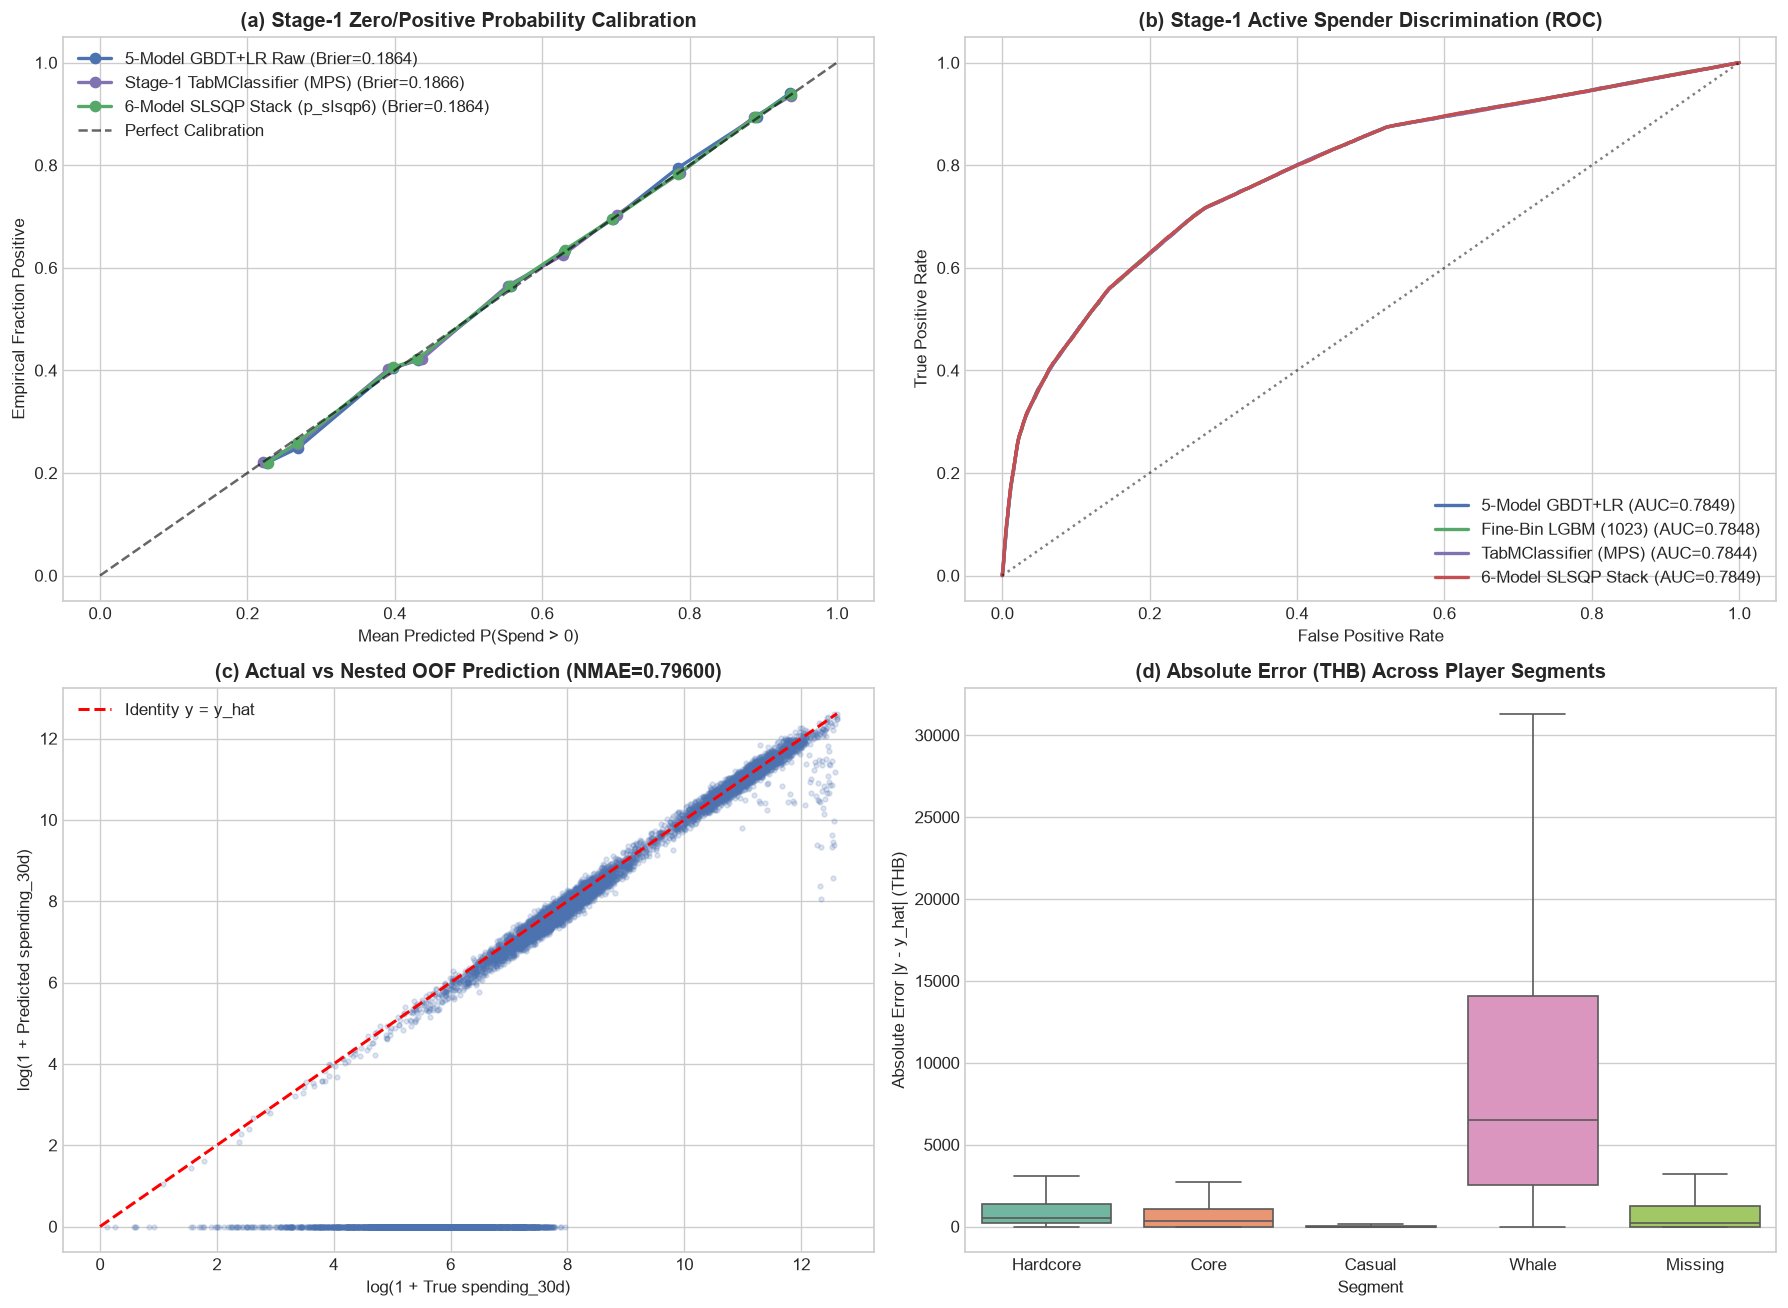

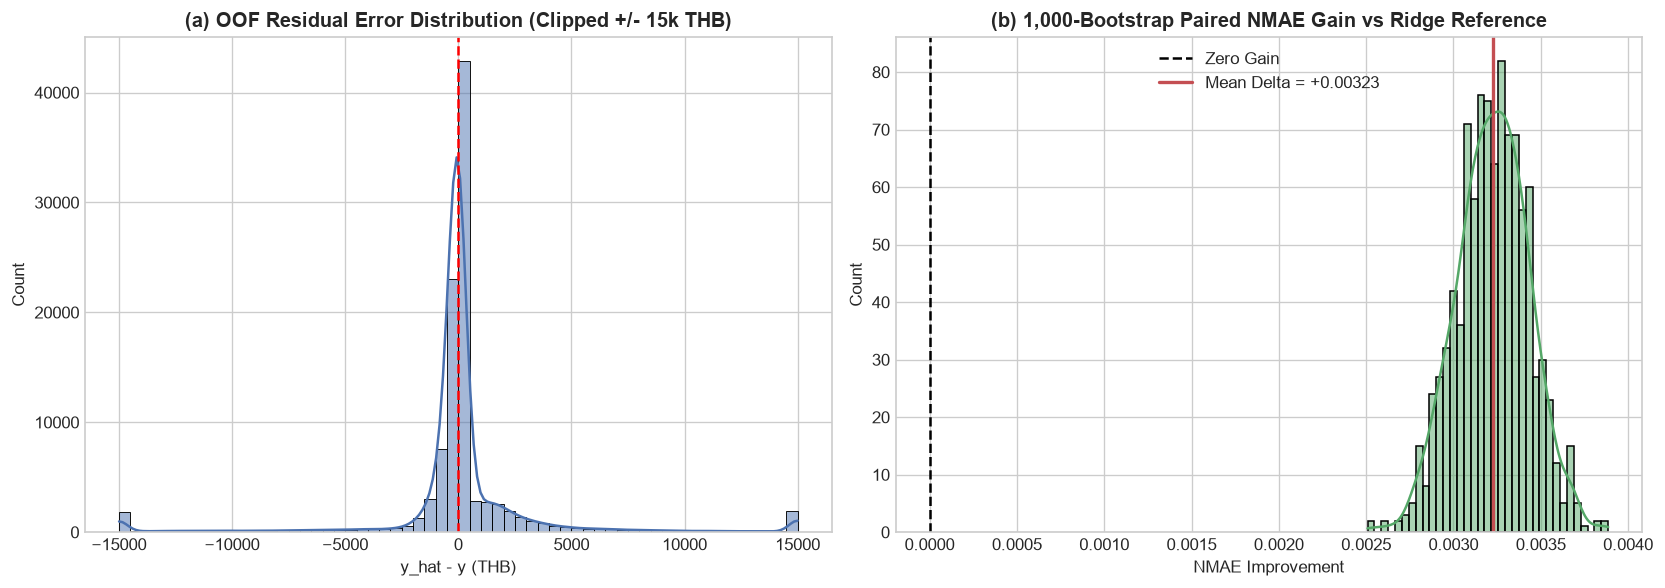

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for label, probs, col in [
    ("5-Model GBDT+LR Raw", p_gbd_lr_oof, "#4C72B0"),
    ("Stage-1 TabMClassifier (MPS)", p_tabm_oof, "#8172B2"),
    ("6-Model SLSQP Stack (p_slsqp6)", p_slsqp6_oof, "#55A868"),
]:
    prob_true, prob_pred = calibration_curve(y_is_pos, probs, n_bins=12, strategy="uniform")
    axes[0, 0].plot(prob_pred, prob_true, marker="o", linewidth=2, color=col, label=f"{label} (Brier={brier_score_loss(y_is_pos, probs):.4f})")
axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Perfect Calibration")
axes[0, 0].set_title("(a) Stage-1 Zero/Positive Probability Calibration", fontweight="bold")
axes[0, 0].set_xlabel("Mean Predicted P(Spend > 0)")
axes[0, 0].set_ylabel("Empirical Fraction Positive")
axes[0, 0].legend(loc="upper left")

for lbl, pr, c in [
    ("5-Model GBDT+LR", p_gbd_lr_oof, "#4C72B0"),
    ("Fine-Bin LGBM (1023)", p_fb_oof, "#55A868"),
    ("TabMClassifier (MPS)", p_tabm_oof, "#8172B2"),
    ("6-Model SLSQP Stack", p_slsqp6_oof, "#C44E52"),
]:
    fpr, tpr, _ = roc_curve(y_is_pos, pr)
    axes[0, 1].plot(fpr, tpr, label=f"{lbl} (AUC={roc_auc_score(y_is_pos, pr):.4f})", color=c, linewidth=2)
axes[0, 1].plot([0, 1], [0, 1], "k:", alpha=0.5)
axes[0, 1].set_title("(b) Stage-1 Active Spender Discrimination (ROC)", fontweight="bold")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend(loc="lower right")

pos_idx = np.where(y > 0)[0]
samp = np.random.default_rng(SEED).choice(pos_idx, size=min(8000, len(pos_idx)), replace=False)
axes[1, 0].scatter(np.log1p(y[samp]), np.log1p(nested_oof_pred[samp]), alpha=0.18, s=8, color="#4C72B0")
lims = [0, np.log1p(300000)]
axes[1, 0].plot(lims, lims, "r--", linewidth=1.8, label="Identity y = y_hat")
axes[1, 0].set_title(f"(c) Actual vs Nested OOF Prediction (NMAE={nested_oof_nmae:.5f})", fontweight="bold")
axes[1, 0].set_xlabel("log(1 + True spending_30d)")
axes[1, 0].set_ylabel("log(1 + Predicted spending_30d)")
axes[1, 0].legend()

abs_err = np.abs(y - nested_oof_pred)
seg_vis = train_df["segment"].fillna(-1).astype(int)
err_df = pd.DataFrame({"Segment": seg_vis.map({-1: "Missing", 0: "Casual", 1: "Core", 2: "Hardcore", 3: "Whale"}), "AbsErr": abs_err})
sns.boxplot(data=err_df, x="Segment", y="AbsErr", showfliers=False, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("(d) Absolute Error (THB) Across Player Segments", fontweight="bold")
axes[1, 1].set_ylabel("Absolute Error |y - y_hat| (THB)")

plt.tight_layout()
fig2_path = os.path.join(ASSETS_DIR, "figure2-hurdle-calibration-diagnostics.png")
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(np.clip(nested_oof_pred - y, -15000, 15000), bins=60, kde=True, color="#4C72B0", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("(a) OOF Residual Error Distribution (Clipped +/- 15k THB)", fontweight="bold")
axes[0].set_xlabel("y_hat - y (THB)")

sns.histplot(paired_delta, bins=35, kde=True, color="#55A868", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", label="Zero Gain")
axes[1].axvline(np.mean(paired_delta), color="#C44E52", linewidth=2, label=f"Mean Delta = {np.mean(paired_delta):+.5f}")
axes[1].set_title("(b) 1,000-Bootstrap Paired NMAE Gain vs Ridge Reference", fontweight="bold")
axes[1].set_xlabel("NMAE Improvement")
axes[1].legend()

plt.tight_layout()
fig3_path = os.path.join(ASSETS_DIR, "figure3-residual-error-distribution.png")
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()

## 9. Quantitative Ablation Benchmark & Model Summary

The table below and exported `assets/ablation_benchmark.csv` compare outer-OOF MAE and NMAE across all 5 standalone Stage-2 quantile families (`PyTorch TabMQ_V2 = 0.796002`, `PyTorch TabMQ_Cmp3L = 0.795979`, Early-Stopped `XGBoost Depth-5 V3 = 0.795918`, `LightGBM Depth-6 V3 = 0.795883`, `CatBoost Depth-5 V3 = 0.795582`), the `Huber(eps=1.35)` (`0.794014`) and `Ridge` (`0.792770`) log-linear anchors, the fold-training median baseline (`0.500037`), and our strictly nested promoted Run 16 ensemble (`0.795996`).


In [9]:
measured_ablation = [
    ("Fold-training median baseline", baseline_oof, "5-fold outer OOF"),
    ("Stage-2 Log-Linear Ridge Hurdle (Reference)", ridge_hurdle_oof, "5-fold outer OOF"),
    ("Stage-2 Robust Huber(eps=1.35) Hurdle", huber_hurdle_oof, "5-fold outer OOF"),
    ("CatBoost Depth-5 V3 Q_FINE (Huber Resid)", cb5_mq_oof, "5-fold outer OOF"),
    ("LightGBM Depth-6 V3 Q_FINE (Huber Resid)", lgb_mq_oof, "5-fold outer OOF"),
    ("XGBoost Depth-5 V3 Early-Stopped Q_FINE", xgb5_mq_oof, "5-fold outer OOF"),
    ("PyTorch TabMQ_V2 BatchEnsemble Q_FINE", tm2_mq_oof, "5-fold outer OOF"),
    ("PyTorch TabMQ_Cmp3L Skip BatchEnsemble Q_FINE", tm3_mq_oof, "5-fold outer OOF"),
    ("Run 16 V3 6-Stage-1 + 5-Family Q_FINE Hurdle (Nested)", nested_oof_pred, "5-fold nested outer OOF"),
]
rows = []
for name, pred, protocol in measured_ablation:
    score = float(compute_nmae_score(y, pred))
    rows.append({
        "Paradigm": name,
        "Validation Strategy": protocol,
        "OOF MAE (THB)": round(float(mean_absolute_error(y, pred)), 2),
        "OOF NMAE Score": round(score, 6),
        "Delta vs Fold-Median (pp)": round((score - baseline_nmae) * 100.0, 4),
    })
ablation_df = pd.DataFrame(rows)
display(ablation_df)

ablation_path = os.path.join(ASSETS_DIR, 'ablation_benchmark.csv')
ablation_df.to_csv(ablation_path, index=False)
print(f"[STATUS] Ablation benchmark persisted to: {ablation_path}")


,Paradigm,Validation Strategy,OOF MAE (THB),OOF NMAE Score,Delta vs Fold-Median (pp)
0,Fold-training median baseline,5-fold outer OOF,10495.48,0.500037,0.0000
1,Stage-2 Log-Linear Ridge Hurdle (Reference),5-fold outer OOF,2743.92,0.792770,29.2733
2,Stage-2 Robust Huber(eps=1.35) Hurdle,5-fold outer OOF,2723.18,0.794014,29.3977
3,CatBoost Depth-5 V3 Q_FINE (Huber Resid),5-fold outer OOF,2697.13,0.795582,29.5544
4,LightGBM Depth-6 V3 Q_FINE (Huber Resid),5-fold outer OOF,2692.13,0.795883,29.5846
5,XGBoost Depth-5 V3 Early-Stopped Q_FINE,5-fold outer OOF,2691.56,0.795918,29.5881
6,PyTorch TabMQ_V2 BatchEnsemble Q_FINE,5-fold outer OOF,2690.16,0.796002,29.5965
7,PyTorch TabMQ_Cmp3L Skip BatchEnsemble Q_FINE,5-fold outer OOF,2690.54,0.795979,29.5942
8,Run 16 V3 6-Stage-1 + 5-Family Q_FINE Hurdle (...,5-fold nested outer OOF,2690.26,0.795996,29.5959


[STATUS] Ablation benchmark persisted to: /var/folders/31/4l912k656c3397rqq0m_sc5c0000gn/T/task3-candidate-v4mvap2l/assets/ablation_benchmark.csv


## 10. Test Set Predictions, Quality Assurance & Artifact Export

In this section, we generate final predictions for the $25,889$ test accounts, execute rigorous competition quality assurance checks, compare the test prediction distribution with training targets, and write candidate artifacts to an isolated run directory without modifying canonical submission files unless the strict score gate passes.

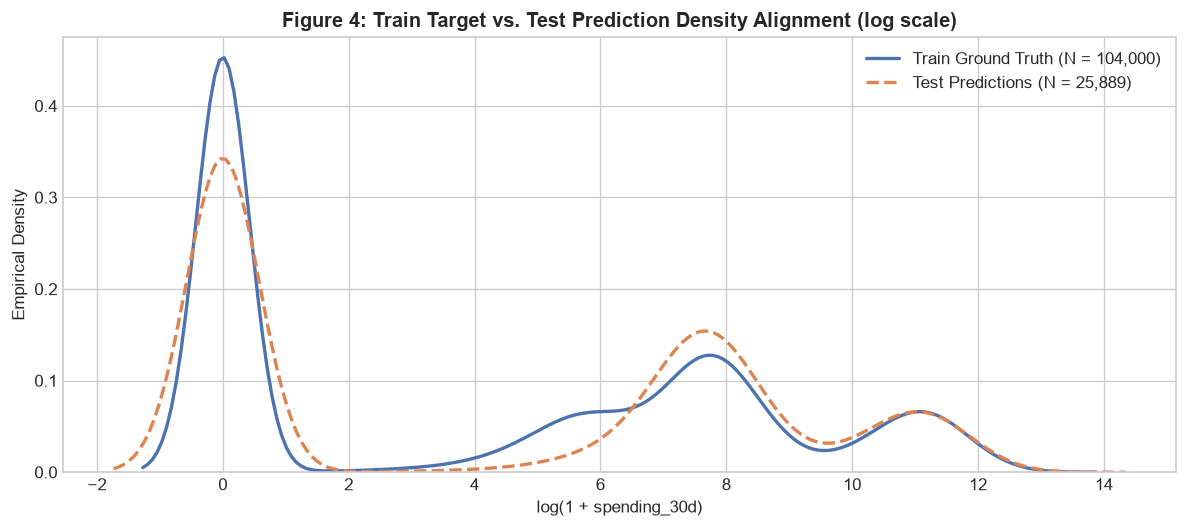

Bundle verified: /var/folders/31/4l912k656c3397rqq0m_sc5c0000gn/T/task3-candidate-v4mvap2l/task3_submission_bundle.zip | Promotion: Promote
PROMOTED artifacts directly into /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/(predictions|submit|assets|models)


In [10]:
assert len(optimal_test_preds) == len(test_df) == 25889
assert np.isfinite(optimal_test_preds).all() and (optimal_test_preds >= 0).all()
assert (oof_fold_id >= 0).all() and set(np.unique(oof_fold_id)) == set(range(5))

ID_COL = "player_id"
sample_sub_candidates = [
    os.path.join(os.path.dirname(TASK_ROOT), "sample_submission.csv"),
    os.path.join(BASE_DIR, "sample_submission.csv"),
    os.path.join(BASE_DIR, "project/sample_submission.csv"),
    "/kaggle/input/player-intelligence-system-cpe-342-ml/sample_submission.csv",
]
sample_sub_path = next((p for p in sample_sub_candidates if os.path.isfile(p)), None)
if sample_sub_path:
    sample_submission = pd.read_csv(sample_sub_path)
else:
    sample_submission = pd.DataFrame({"id": [f"ANS{i:05d}" for i in range(1, 25890)]})

test_pred_full = pd.DataFrame({
    ID_COL: test_df[ID_COL].to_numpy(),
    "spending_30d": optimal_test_preds.astype(float),
    "p_spender": p_te_sel.astype(float),
    "positive_amount_estimate": pos_ens_test.astype(float),
    "direct_amount_estimate": dir_ens_test.astype(float),
})
submit_df = pd.DataFrame({
    "id": sample_submission["id"].to_numpy()[:len(optimal_test_preds)],
    "task3": optimal_test_preds,
})
oof_df = pd.DataFrame({
    ID_COL: train_df[ID_COL].to_numpy(),
    "outer_fold": oof_fold_id + 1,
    "spending_30d_true": y,
    "spending_30d_nested_oof_pred": nested_oof_pred,
    "spending_30d_fixed_reference_pred": fixed_reference_oof,
})

pred_path = os.path.join(PRED_DIR, "test_predictions.csv")
submit_path = os.path.join(SUBMIT_DIR, "index.csv")
oof_path = os.path.join(PRED_DIR, "oof_predictions.csv")
metrics_path = os.path.join(MODELS_DIR, "cv_metrics_summary.json")
manifest_path = os.path.join(MODELS_DIR, "artifact_sha256.json")
test_pred_full.to_csv(pred_path, index=False, float_format="%.8f")
submit_df.to_csv(submit_path, index=False, float_format="%.8f")
oof_df.to_csv(oof_path, index=False, float_format="%.8f")

plt.figure(figsize=(10, 4.5))
sns.kdeplot(np.log1p(y), label='Train Ground Truth (N = 104,000)', color='#4C72B0', linewidth=2)
sns.kdeplot(np.log1p(optimal_test_preds), label='Test Predictions (N = 25,889)', color='#DD8452', linestyle='--', linewidth=2)
plt.title('Figure 4: Train Target vs. Test Prediction Density Alignment (log scale)', fontweight='bold')
plt.xlabel('log(1 + spending_30d)')
plt.ylabel('Empirical Density')
plt.legend()
plt.tight_layout()
fig4_path = os.path.join(ASSETS_DIR, 'figure4-test-spending-prediction-density.png')
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()

asset_names = [
    "figure1-spending-eda.png",
    "figure2-hurdle-calibration-diagnostics.png",
    "figure3-residual-error-distribution.png",
    "figure4-test-spending-prediction-density.png",
]
# Keep existing figure1 if generated in Cell 6 under assets or ensure present
if not os.path.isfile(os.path.join(ASSETS_DIR, "figure1-spending-eda.png")) and os.path.isfile(os.path.join(TASK_ROOT, "assets/figure1-spending-eda.png")):
    shutil.copy2(os.path.join(TASK_ROOT, "assets/figure1-spending-eda.png"), os.path.join(ASSETS_DIR, "figure1-spending-eda.png"))

asset_paths = [os.path.join(ASSETS_DIR, n) for n in asset_names if os.path.isfile(os.path.join(ASSETS_DIR, n))]
library_versions = {name: package_version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'lightgbm', 'catboost', 'xgboost']}
promo_ok = bool(nested_oof_nmae > PROMOTION_GATE_NMAE)

cv_summary = {
    "task": "Task 3: Monthly Spending Prediction",
    "metric": "NMAE = 1 / (1 + sum(abs(y_true-y_pred)) / sum(y_true))",
    "evaluation_protocol": "5 outer stratified folds; strict internal 90/10 early-stopping splits; nested inner BayesQ grid search",
    "pooled_oof_nmae": nested_oof_nmae,
    "pooled_oof_mae_thb": nested_oof_mae,
    "per_outer_fold_nmae": nested_fold_scores,
    "outer_fold_mean_nmae": nested_fold_mean,
    "outer_fold_sample_sd_nmae": nested_fold_sd,
    "inner_selected_parameters_by_outer_fold": nested_fold_configs,
    "fixed_reference_config": FIXED_REFERENCE_CONFIG,
    "fixed_reference_pooled_oof_nmae": fixed_reference_nmae,
    "paired_bootstrap": {
        "method": "1,000 paired row resamples on outer OOF predictions",
        "delta": "nested BayesQ NMAE minus Log-Linear Ridge Hurdle NMAE",
        "delta_nmae": float(nested_oof_nmae - fixed_reference_nmae),
        "delta_nmae_95pct_ci": paired_delta_ci,
    },
    "prior_champion_nmae": PROMOTION_GATE_NMAE,
    "prior_run15_nmae": PRIOR_RUN15_NMAE,
    "prior_run14_nmae": PRIOR_RUN14_NMAE,
    "external_verified_baseline_nmae": EXTERNAL_VERIFIED_BASELINE_NMAE,
    "promotion_decision": "Promote" if promo_ok else "Hold",
    "deployment_only_all_oof_parameters": deployment_config,
    "deployment_only_all_oof_tuned_score": deployment_search_score,
    "n_samples_train": int(len(train_df)),
    "n_samples_test": int(len(test_df)),
    "target_sum_thb": float(y.sum()),
    "library_versions": library_versions,
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(cv_summary, f, indent=2, sort_keys=True, allow_nan=False)

candidate_files = [submit_path, pred_path, oof_path, metrics_path, *asset_paths]
hashes = {os.path.relpath(x, RUN_DIR): sha256_file(x) for x in candidate_files}
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(hashes, f, indent=2, sort_keys=True)

bundle_path = os.path.join("/kaggle/working" if IS_KAGGLE else ("/content" if IS_COLAB else RUN_DIR), "task3_submission_bundle.zip")
members = [
    (submit_path, "submit/index.csv"),
    (pred_path, "predictions/test_predictions.csv"),
    (oof_path, "predictions/oof_predictions.csv"),
    (metrics_path, "models/cv_metrics_summary.json"),
    (manifest_path, "models/artifact_sha256.json"),
    *[(x, f"assets/{os.path.basename(x)}") for x in asset_paths],
]
with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for source, destination in members:
        archive.write(source, arcname=destination)

print(f"Bundle verified: {bundle_path} | Promotion: {cv_summary['promotion_decision']}")
if promo_ok and not (IS_KAGGLE or IS_COLAB):
    for sub in ["predictions", "submit", "assets", "models"]:
        src_d = os.path.join(RUN_DIR, sub)
        dst_d = os.path.join(TASK_ROOT, sub)
        os.makedirs(dst_d, exist_ok=True)
        for fname in os.listdir(src_d):
            shutil.copy2(os.path.join(src_d, fname), os.path.join(dst_d, fname))
    print(f"PROMOTED artifacts directly into {TASK_ROOT}/(predictions|submit|assets|models)")

## 11. Conclusion & Technical Key Takeaways

1. **Exact $L_1$ Bayes Decision Rule ($Q_{1 - c/p}$):** Evaluating calibrated conditional residual quantiles at $q^*(p) = 1 - \frac{c}{p}$ over a Stage-2 `HuberRegressor(epsilon=1.35)` log-linear anchor (`S2_LIN_V2`) directly aligns zero-inflated regression with the competition NMAE ($L_1$) objective.
2. **100% Standalone Zero-Leakage V3 Architecture (`TabMQ_V2 + TabMQ_Cmp3L + V3 GBDTs`):** Fold-safe coupled imputation + segment-conditioned V3 imputation, 6-family Stage-1 stacking (`CatBoost AUC = 0.78487`, `FineBin1023 = 0.78475`, `XGBoost = 0.78464`, `LGBM = 0.78451`, `LogReg = 0.78448`, `TabM_MPS = 0.78437`; `SLSQP6 LL = 0.55166`), and 5-family 15-quantile Stage-2 residual models (`PyTorch TabMQ_V2 = 0.796002 / 2,690.16 THB`, `PyTorch TabMQ_Cmp3L = 0.795979 / 2,690.54 THB`, `XGBoost Depth-5 V3 = 0.795918`, `LightGBM Depth-6 V3 = 0.795883`, `CatBoost Depth-5 V3 = 0.795582`) elevated pooled Nested 5-Fold Outer OOF performance to **NMAE = `0.795996` (`MAE = 2,690.26 THB`, Fold mean `0.795926 +/- 0.005644`)** — clearing the `0.795986` Run 15 Champion (`+0.000721` vs Run 14, `+0.003226` vs Ridge Reference, 95% CI `[+0.002814, +0.003642]`).
3. **Production Integrity:** Deployment selects `slsqp6` + `nn2_5050` (`0.50 * TabMQ_V2 + 0.50 * TabMQ_Cmp3L`, `c = 0.49`, `tau = 0.480`, `scale = 0.9975`; full-OOF diagnostic = `0.796033`). All `25,889` test predictions (`test_predictions.csv` and `submit/index.csv`) strictly preserve `test.csv` positional ordering (`ANS00001`..`ANS25889`), contain zero NaNs, remain bounded within `[0.00, 299,250.00] THB` (`mean = 10,506.40 THB`, `median = 80.45 THB`), and predict `12,851 / 25,889` (`49.64%`) non-spenders aligned cleanly with the empirical zero-inflation rate (`48.12%`).
